In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

print("Libraries loaded successfully")

Libraries loaded successfully


In [2]:
metadata_path = "../data/raw/HAM10000_metadata.csv"

df = pd.read_csv(metadata_path)

print("Dataset loaded successfully")
print("Number of records:", len(df))


Dataset loaded successfully
Number of records: 10015


In [3]:
df["dx"].value_counts()

dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64

In [4]:
class_names = {
    "akiec": "Actinic Keratoses",
    "bcc": "Basal Cell Carcinoma",
    "bkl": "Benign Keratosis",
    "df": "Dermatofibroma",
    "mel": "Melanoma",
    "nv": "Melanocytic Nevus",
    "vasc": "Vascular Lesion"
}

df["disease_name"] = df["dx"].map(class_names)

df[["dx", "disease_name"]].drop_duplicates()

,dx,disease_name
0,bkl,Benign Keratosis
64,nv,Melanocytic Nevus
1095,df,Dermatofibroma
1211,mel,Melanoma
2320,vasc,Vascular Lesion
2462,bcc,Basal Cell Carcinoma
9687,akiec,Actinic Keratoses


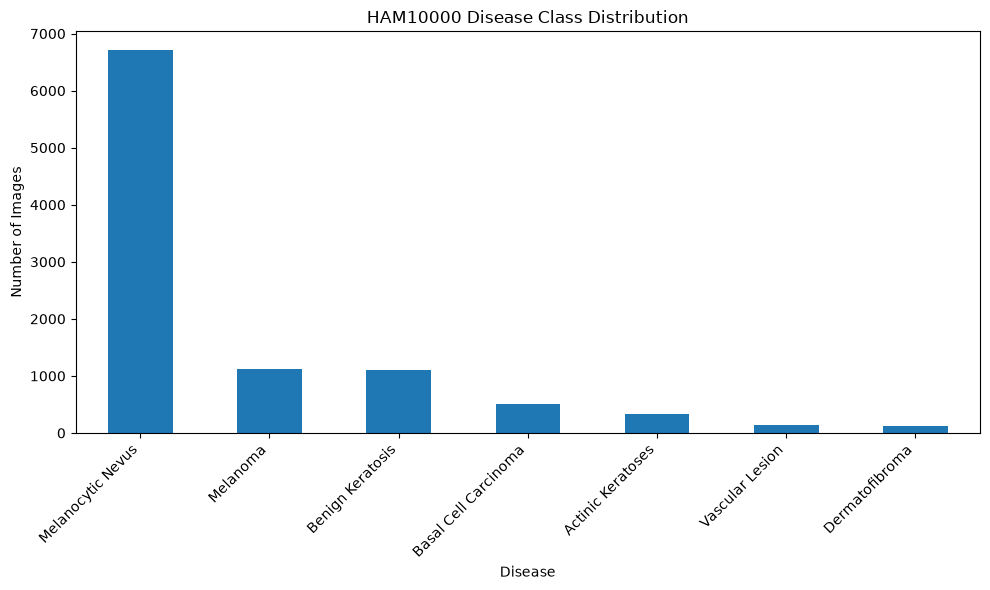

In [5]:
plt.figure(figsize=(10, 6))

class_counts = df["disease_name"].value_counts()
class_counts.plot(kind="bar")

plt.title("HAM10000 Disease Class Distribution")
plt.xlabel("Disease")
plt.ylabel("Number of Images")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [6]:
df.isnull().sum()

lesion_id        0
image_id         0
dx               0
dx_type          0
age             57
sex              0
localization     0
disease_name     0
dtype: int64

In [7]:
print("Duplicate image IDs:", df["image_id"].duplicated().sum())

Duplicate image IDs: 0


In [8]:
print("Total images:", len(df))
print("Unique lesions:", df["lesion_id"].nunique())

Total images: 10015
Unique lesions: 7470


Image ID: ISIC_0027419
Image size: (600, 450)
Image mode: RGB


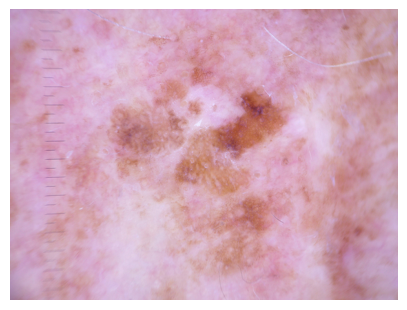

In [9]:
from PIL import Image

image_folder_1 = "../data/raw/HAM10000_images_part_1"
image_folder_2 = "../data/raw/HAM10000_images_part_2"

sample_id = df.iloc[0]["image_id"]

path1 = os.path.join(image_folder_1, sample_id + ".jpg")
path2 = os.path.join(image_folder_2, sample_id + ".jpg")

if os.path.exists(path1):
    image_path = path1
else:
    image_path = path2

image = Image.open(image_path)

print("Image ID:", sample_id)
print("Image size:", image.size)
print("Image mode:", image.mode)

plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.axis("off")
plt.show()

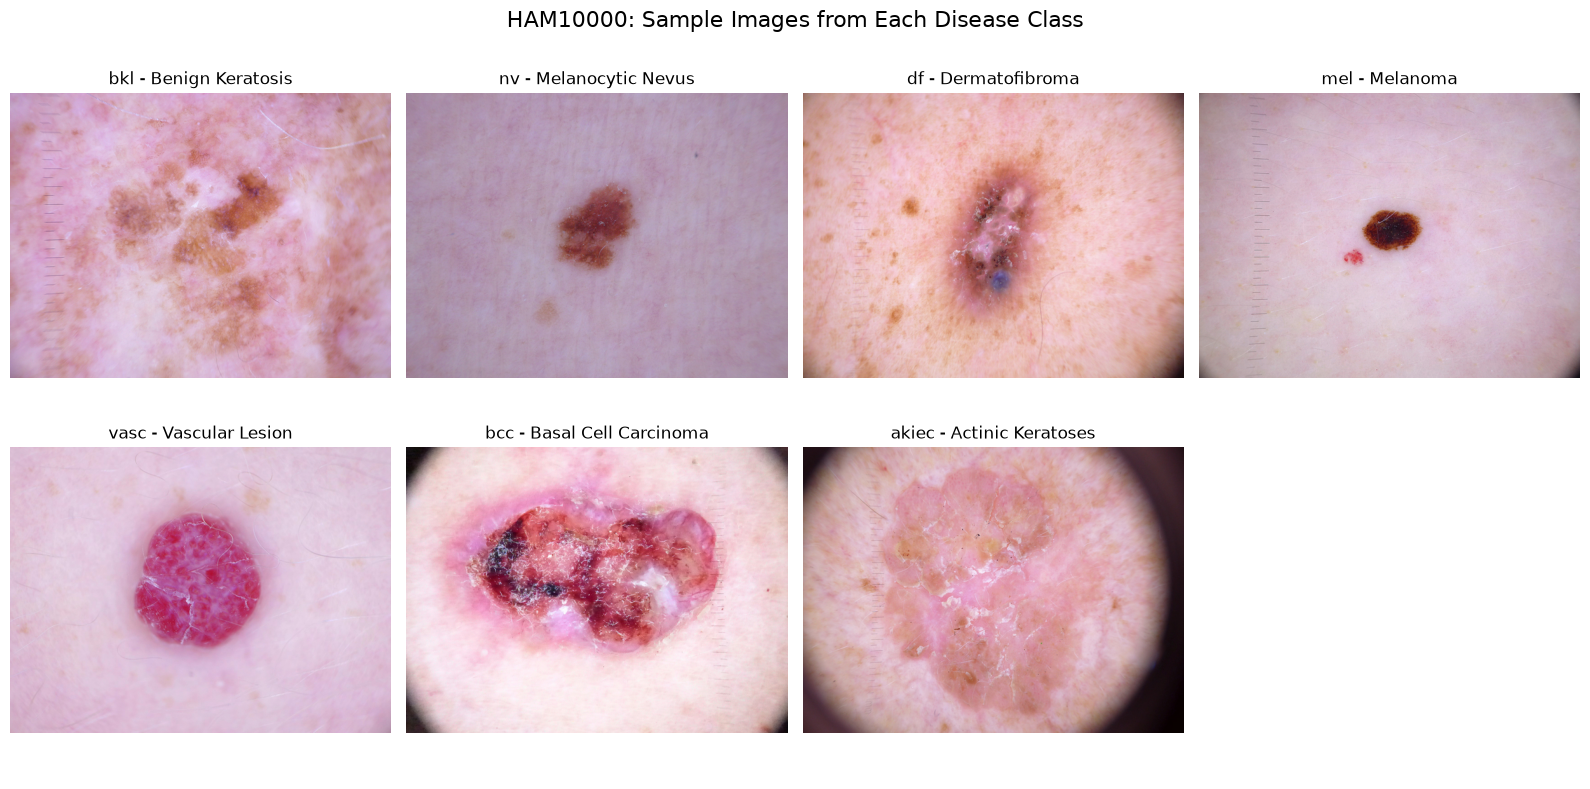

In [10]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

sample_df = df.groupby("dx", group_keys=False).head(1)

for ax, (_, row) in zip(axes.flat, sample_df.iterrows()):
    image_id = row["image_id"]

    path1 = os.path.join(image_folder_1, image_id + ".jpg")
    path2 = os.path.join(image_folder_2, image_id + ".jpg")

    image_path = path1 if os.path.exists(path1) else path2

    image = Image.open(image_path)

    ax.imshow(image)
    ax.set_title(f"{row['dx']} - {row['disease_name']}")
    ax.axis("off")

# Hide the unused 8th subplot
for ax in axes.flat[len(sample_df):]:
    ax.axis("off")

plt.suptitle("HAM10000: Sample Images from Each Disease Class", fontsize=16)
plt.tight_layout()
plt.show()

In [11]:
from sklearn.model_selection import train_test_split

# Get one row per lesion
lesion_df = df[["lesion_id", "dx"]].drop_duplicates("lesion_id")

print("Total unique lesions:", len(lesion_df))

Total unique lesions: 7470


In [12]:
train_lesions, temp_lesions = train_test_split(
    lesion_df,
    test_size=0.30,
    stratify=lesion_df["dx"],
    random_state=42
)

val_lesions, test_lesions = train_test_split(
    temp_lesions,
    test_size=0.50,
    stratify=temp_lesions["dx"],
    random_state=42
)

print("Training lesions:", len(train_lesions))
print("Validation lesions:", len(val_lesions))
print("Testing lesions:", len(test_lesions))

Training lesions: 5229
Validation lesions: 1120
Testing lesions: 1121


In [13]:
train_ids = set(train_lesions["lesion_id"])
val_ids = set(val_lesions["lesion_id"])
test_ids = set(test_lesions["lesion_id"])

df["split"] = df["lesion_id"].apply(
    lambda x: "train" if x in train_ids
    else "val" if x in val_ids
    else "test"
)

print(df["split"].value_counts())

split
train    7002
val      1532
test     1481
Name: count, dtype: int64


In [14]:
train_set = set(df[df["split"] == "train"]["lesion_id"])
val_set = set(df[df["split"] == "val"]["lesion_id"])
test_set = set(df[df["split"] == "test"]["lesion_id"])

print("Train-Val overlap:", len(train_set & val_set))
print("Train-Test overlap:", len(train_set & test_set))
print("Val-Test overlap:", len(val_set & test_set))

Train-Val overlap: 0
Train-Test overlap: 0
Val-Test overlap: 0


In [15]:
split_path = "../data/processed/ham10000_split.csv"

df.to_csv(split_path, index=False)

print("Split saved successfully!")
print("Saved to:", split_path)

Split saved successfully!
Saved to: ../data/processed/ham10000_split.csv


In [16]:
print(df.groupby(["split", "disease_name"]).size())

split  disease_name        
test   Actinic Keratoses         46
       Basal Cell Carcinoma      71
       Benign Keratosis         168
       Dermatofibroma            20
       Melanocytic Nevus        992
       Melanoma                 165
       Vascular Lesion           19
train  Actinic Keratoses        230
       Basal Cell Carcinoma     366
       Benign Keratosis         774
       Dermatofibroma            76
       Melanocytic Nevus       4679
       Melanoma                 778
       Vascular Lesion           99
val    Actinic Keratoses         51
       Basal Cell Carcinoma      77
       Benign Keratosis         157
       Dermatofibroma            19
       Melanocytic Nevus       1034
       Melanoma                 170
       Vascular Lesion           24
dtype: int64


In [17]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

print("TensorFlow version:", tf.__version__)
print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

TensorFlow version: 2.21.0
Image size: (224, 224)
Batch size: 32


In [18]:
def get_image_path(image_id):
    path1 = os.path.join(image_folder_1, image_id + ".jpg")
    path2 = os.path.join(image_folder_2, image_id + ".jpg")

    if os.path.exists(path1):
        return path1
    elif os.path.exists(path2):
        return path2
    else:
        return None

df["image_path"] = df["image_id"].apply(get_image_path)

print("Images found:", df["image_path"].notna().sum())
print("Images missing:", df["image_path"].isna().sum())

Images found: 10015
Images missing: 0


In [19]:
label_map = {
    "akiec": 0,
    "bcc": 1,
    "bkl": 2,
    "df": 3,
    "mel": 4,
    "nv": 5,
    "vasc": 6
}

df["label"] = df["dx"].map(label_map)

print(df[["dx", "label"]].drop_duplicates().sort_values("label"))

         dx  label
9687  akiec      0
2462    bcc      1
0       bkl      2
1095     df      3
1211    mel      4
64       nv      5
2320   vasc      6


In [20]:
def load_image(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0
    
    return image, label

In [21]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomContrast(0.1)
])

print("Data augmentation pipeline created!")

Data augmentation pipeline created!


In [22]:
train_df = df[df["split"] == "train"].copy()
val_df = df[df["split"] == "val"].copy()
test_df = df[df["split"] == "test"].copy()

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

Training images: 7002
Validation images: 1532
Testing images: 1481


In [23]:
def create_dataset(dataframe, training=False):
    paths = dataframe["image_path"].values
    labels = dataframe["label"].values

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=42
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if training:
        dataset = dataset.map(
            lambda image, label: (data_augmentation(image, training=True), label),
            num_parallel_calls=tf.data.AUTOTUNE
        )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset

In [24]:
train_ds = create_dataset(train_df, training=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

print("TensorFlow datasets created successfully!")

TensorFlow datasets created successfully!


In [25]:
images, labels = next(iter(train_ds))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Pixel range:", images.numpy().min(), "to", images.numpy().max())

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Pixel range: 0.0 to 1.0072918


In [26]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomContrast(0.1),
    tf.keras.layers.Rescaling(1.0, offset=0.0)
])

print("Data augmentation pipeline created!")

Data augmentation pipeline created!


In [27]:
def create_dataset(dataframe, training=False):
    paths = dataframe["image_path"].values
    labels = dataframe["label"].values

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=42
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if training:
        dataset = dataset.map(
            lambda image, label: (
                tf.clip_by_value(
                    data_augmentation(image, training=True),
                    0.0,
                    1.0
                ),
                label
            ),
            num_parallel_calls=tf.data.AUTOTUNE
        )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset

In [28]:
train_ds = create_dataset(train_df, training=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

print("Datasets recreated successfully!")

Datasets recreated successfully!


In [29]:
images, labels = next(iter(train_ds))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Pixel range:", images.numpy().min(), "to", images.numpy().max())

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Pixel range: 0.0 to 1.0


In [30]:
baseline_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3)),

    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(128, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.GlobalAveragePooling2D(),

    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.4),

    tf.keras.layers.Dense(7, activation="softmax")
])

baseline_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 222, 222, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 111, 111, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 109, 109, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 54, 54, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 52, 52, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 26, 26, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 128)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 7)                   │             903 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 110,663 (432.28 KB)

 Trainable params: 110,663 (432.28 KB)

 Non-trainable params: 0 (0.00 B)

In [31]:
baseline_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Baseline model compiled successfully!")

Baseline model compiled successfully!


In [32]:
history_baseline = baseline_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10


C:\Users\Lenovo\OneDrive\Desktop\Skin disease detector\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


 34/219 ━━━━━━━━━━━━━━━━━━━━ 3:02 985ms/step - accuracy: 0.6645 - loss: 1.3033


KeyboardInterrupt



KeyboardInterrupt: 

In [33]:
test_loss, test_accuracy = baseline_model.evaluate(test_ds)

print("Baseline Test Loss:", test_loss)
print("Baseline Test Accuracy:", test_accuracy)

27/47 ━━━━━━━━━━━━━━━━━━━━ 6s 334ms/step - accuracy: 0.4873 - loss: 1.5385

KeyboardInterrupt: 

In [34]:
plt.figure(figsize=(8, 5))

plt.plot(history_baseline.history["accuracy"], label="Training Accuracy")
plt.plot(history_baseline.history["val_accuracy"], label="Validation Accuracy")

plt.title("Baseline CNN - Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()

NameError: name 'history_baseline' is not defined

<Figure size 800x500 with 0 Axes>

In [35]:
plt.figure(figsize=(8, 5))

plt.plot(history_baseline.history["loss"], label="Training Loss")
plt.plot(history_baseline.history["val_loss"], label="Validation Loss")

plt.title("Baseline CNN - Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()

NameError: name 'history_baseline' is not defined

<Figure size 800x500 with 0 Axes>

In [36]:
import numpy as np

y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = baseline_model.predict(images, verbose=0)
    
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Predictions generated successfully!")
print("Number of test samples:", len(y_true))

Predictions generated successfully!
Number of test samples: 1481


In [37]:
from sklearn.metrics import classification_report

target_names = [
    "Actinic Keratoses",
    "Basal Cell Carcinoma",
    "Benign Keratosis",
    "Dermatofibroma",
    "Melanoma",
    "Melanocytic Nevus",
    "Vascular Lesion"
]

print(
    classification_report(
        y_true,
        y_pred,
        target_names=target_names,
        digits=4
    )
)

                      precision    recall  f1-score   support

   Actinic Keratoses     0.0000    0.0000    0.0000        46
Basal Cell Carcinoma     0.0000    0.0000    0.0000        71
    Benign Keratosis     0.0000    0.0000    0.0000       168
      Dermatofibroma     0.0000    0.0000    0.0000        20
            Melanoma     0.0000    0.0000    0.0000       165
   Melanocytic Nevus     0.6698    1.0000    0.8023       992
     Vascular Lesion     0.0000    0.0000    0.0000        19

            accuracy                         0.6698      1481
           macro avg     0.0957    0.1429    0.1146      1481
        weighted avg     0.4487    0.6698    0.5374      1481



C:\Users\Lenovo\OneDrive\Desktop\Skin disease detector\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Lenovo\OneDrive\Desktop\Skin disease detector\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Lenovo\OneDrive\Desktop\Skin disease detector\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.


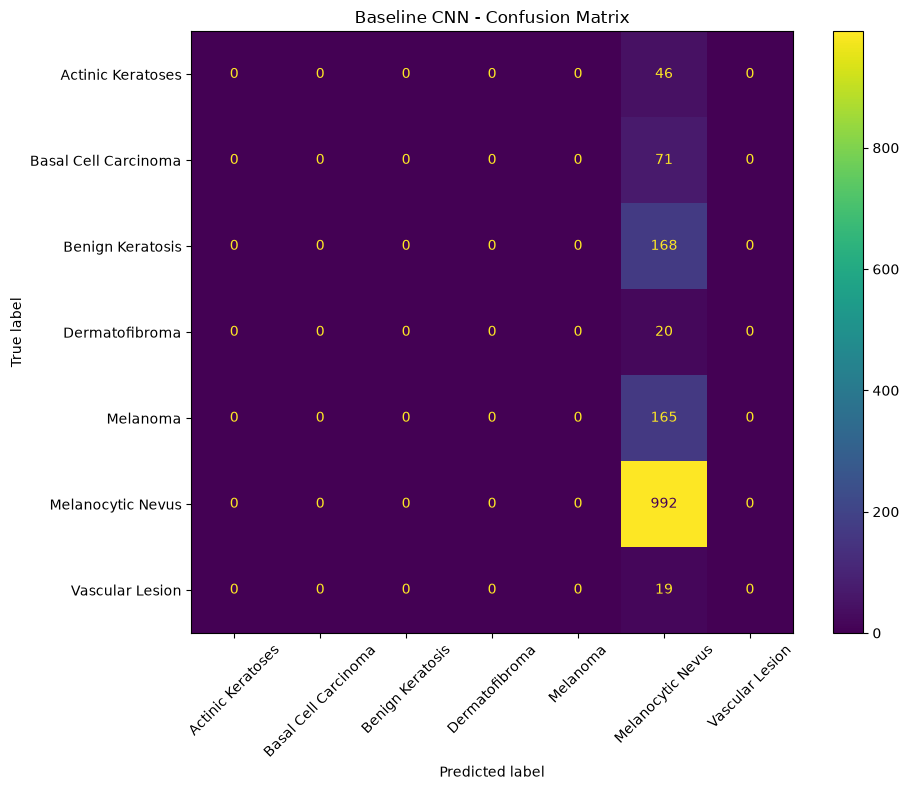

In [38]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=target_names
)

disp.plot(
    ax=ax,
    xticks_rotation=45,
    values_format="d"
)

plt.title("Baseline CNN - Confusion Matrix")
plt.tight_layout()
plt.show()

In [39]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(train_df["label"])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["label"]
)

class_weights = dict(zip(classes, weights))

print("Class weights:")
for class_id, weight in class_weights.items():
    print(f"{class_id} - {target_names[class_id]}: {weight:.4f}")

Class weights:
0 - Actinic Keratoses: 4.3491
1 - Basal Cell Carcinoma: 2.7330
2 - Benign Keratosis: 1.2924
3 - Dermatofibroma: 13.1617
4 - Melanoma: 1.2857
5 - Melanocytic Nevus: 0.2138
6 - Vascular Lesion: 10.1039


In [40]:
base_model = tf.keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

base_model.trainable = False

efficientnet_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3)),
    base_model,

    tf.keras.layers.GlobalAveragePooling2D(),

    tf.keras.layers.BatchNormalization(),

    tf.keras.layers.Dense(
        256,
        activation="relu"
    ),

    tf.keras.layers.Dropout(0.4),

    tf.keras.layers.Dense(
        7,
        activation="softmax"
    )
])

efficientnet_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)          │ (None, 7, 7, 1280)          │       4,049,571 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_1           │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 1280)                │           5,120 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 256)                 │         327,936 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 7)                   │           1,799 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 4,384,426 (16.73 MB)

 Trainable params: 332,295 (1.27 MB)

 Non-trainable params: 4,052,131 (15.46 MB)

In [41]:
efficientnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("EfficientNet model compiled successfully!")

EfficientNet model compiled successfully!


In [42]:
history_efficientnet = efficientnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=class_weights
)

C:\Users\Lenovo\OneDrive\Desktop\Skin disease detector\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/10


KeyboardInterrupt: 

In [43]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(train_df["label"])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["label"]
)

class_weights = dict(zip(classes, weights))

print("Class weights created:")
print(class_weights)

Class weights created:
{np.int64(0): np.float64(4.349068322981366), np.int64(1): np.float64(2.7330210772833725), np.int64(2): np.float64(1.2923588039867109), np.int64(3): np.float64(13.161654135338345), np.int64(4): np.float64(1.2857142857142858), np.int64(5): np.float64(0.21378194363875064), np.int64(6): np.float64(10.103896103896103)}


In [44]:
history_efficientnet = efficientnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=class_weights
)

Epoch 1/10


C:\Users\Lenovo\OneDrive\Desktop\Skin disease detector\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


SystemError: D:\a\1\s\Objects\listobject.c:546: bad argument to internal function

In [45]:
efficientnet_model.save("../models/efficientnet_skin_disease.keras")

print("EfficientNet model saved successfully!")

EfficientNet model saved successfully!


In [46]:
test_loss_eff, test_accuracy_eff = efficientnet_model.evaluate(test_ds)

print("EfficientNet Test Loss:", test_loss_eff)
print("EfficientNet Test Accuracy:", test_accuracy_eff)

 7/47 ━━━━━━━━━━━━━━━━━━━━ 40s 1s/step - accuracy: 0.0893 - loss: 1.9474

KeyboardInterrupt: 

In [47]:
print("Test label distribution:")
print(test_df["label"].value_counts().sort_index())

print("\nPredicted label distribution:")

test_predictions = efficientnet_model.predict(test_ds, verbose=1)
predicted_labels = np.argmax(test_predictions, axis=1)

print(np.bincount(predicted_labels, minlength=7))

Test label distribution:
label
0     46
1     71
2    168
3     20
4    165
5    992
6     19
Name: count, dtype: int64

Predicted label distribution:
 4/47 ━━━━━━━━━━━━━━━━━━━━ 39s 929ms/step

KeyboardInterrupt: 

In [ ]:
print("Prediction probabilities for the first 5 test images:")

for i in range(5):
    probs = test_predictions[i]
    print(f"\nImage {i + 1}")
    print("Predicted class:", np.argmax(probs))
    print("Probabilities:", np.round(probs, 4))

In [ ]:
def load_image_for_efficientnet(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)

    return image, label


def create_efficientnet_dataset(dataframe, training=False):
    paths = dataframe["image_path"].values
    labels = dataframe["label"].values

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=42
        )

    dataset = dataset.map(
        load_image_for_efficientnet,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if training:
        dataset = dataset.map(
            lambda image, label: (
                tf.clip_by_value(
                    data_augmentation(image / 255.0, training=True) * 255.0,
                    0.0,
                    255.0
                ),
                label
            ),
            num_parallel_calls=tf.data.AUTOTUNE
        )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


train_eff_ds = create_efficientnet_dataset(train_df, training=True)
val_eff_ds = create_efficientnet_dataset(val_df)
test_eff_ds = create_efficientnet_dataset(test_df)

print("Corrected EfficientNet datasets created!")

In [ ]:
base_model = tf.keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

base_model.trainable = False

efficientnet_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3)),
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Dense(7, activation="softmax")
])

efficientnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Corrected EfficientNet model ready!")

In [ ]:
history_efficientnet = efficientnet_model.fit(
    train_eff_ds,
    validation_data=val_eff_ds,
    epochs=5,
    class_weight=class_weights
)

In [ ]:
efficientnet_model.save("../models/efficientnet_skin_disease_corrected.keras")

print("Corrected EfficientNet saved successfully!")

In [ ]:
test_loss_eff, test_accuracy_eff = efficientnet_model.evaluate(test_eff_ds)

print("Corrected EfficientNet Test Loss:", test_loss_eff)
print("Corrected EfficientNet Test Accuracy:", test_accuracy_eff)


In [ ]:
print("Best training accuracy:",
      max(history_efficientnet.history["accuracy"]))

print("Best validation accuracy:",
      max(history_efficientnet.history["val_accuracy"]))

print("Final training accuracy:",
      history_efficientnet.history["accuracy"][-1])

print("Final validation accuracy:",
      history_efficientnet.history["val_accuracy"][-1])

In [ ]:
base_model.trainable = True

# Freeze the earlier layers and fine-tune only the last 30 layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

print("Total layers:", len(base_model.layers))
print("Trainable layers:",
      sum(layer.trainable for layer in base_model.layers))

In [ ]:
efficientnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("EfficientNet recompiled for fine-tuning!")


In [ ]:
history_finetune = efficientnet_model.fit(
    train_eff_ds,
    validation_data=val_eff_ds,
    epochs=5,
    class_weight=class_weights
)

In [ ]:
test_loss_final, test_accuracy_final = efficientnet_model.evaluate(test_eff_ds)

print("Final Test Loss:", test_loss_final)
print("Final Test Accuracy:", test_accuracy_final)

In [ ]:
efficientnet_model.save("../models/efficientnet_finetuned.keras")

print("Fine-tuned model saved successfully!")

In [ ]:
y_true_baseline = []
y_pred_baseline = []

for images, labels in test_ds:
    predictions = baseline_model.predict(images, verbose=0)

    y_true_baseline.extend(labels.numpy())
    y_pred_baseline.extend(np.argmax(predictions, axis=1))

y_true_baseline = np.array(y_true_baseline)
y_pred_baseline = np.array(y_pred_baseline)

print("Baseline predictions generated!")
print("Test samples:", len(y_true_baseline))

In [ ]:
from sklearn.metrics import classification_report

target_names = [
    "Actinic Keratoses",
    "Basal Cell Carcinoma",
    "Benign Keratosis",
    "Dermatofibroma",
    "Melanoma",
    "Melanocytic Nevus",
    "Vascular Lesion"
]

print("BASELINE CNN — CLASSIFICATION REPORT")
print("=" * 60)

print(classification_report(
    y_true_baseline,
    y_pred_baseline,
    target_names=target_names,
    digits=4,
    zero_division=0
))

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true_baseline, y_pred_baseline)

plt.figure(figsize=(9, 7))
plt.imshow(cm)

plt.title("Baseline CNN - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.colorbar()

plt.xticks(range(7), target_names, rotation=45, ha="right")
plt.yticks(range(7), target_names)

for i in range(7):
    for j in range(7):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

classes = np.arange(7)

moderate_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["label"].values
)

# Reduce the effect of very large weights
moderate_weights = np.sqrt(moderate_weights)

class_weight_moderate = {
    int(i): float(w)
    for i, w in zip(classes, moderate_weights)
}

print("Moderate Class Weights:")
for i, w in class_weight_moderate.items():
    print(f"{target_names[i]}: {w:.3f}")

In [ ]:
improved_cnn = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3)),

    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(128, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.GlobalAveragePooling2D(),

    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.4),

    tf.keras.layers.Dense(7, activation="softmax")
])

improved_cnn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Improved CNN created successfully!")
print("Training with moderate class weights...")

In [ ]:
history_improved = improved_cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=class_weight_moderate
)

print("Improved CNN training completed!")

In [ ]:
print("Training history available:", history_improved is not None)
print("Epochs completed:", len(history_improved.history["loss"]))
print("Final training accuracy:", history_improved.history["accuracy"][-1])
print("Final validation accuracy:", history_improved.history["val_accuracy"][-1])

In [ ]:
improved_test_loss, improved_test_accuracy = improved_cnn.evaluate(
    test_ds,
    verbose=1
)

print("\nImproved CNN Test Results")
print("=" * 40)
print(f"Test Loss: {improved_test_loss:.4f}")
print(f"Test Accuracy: {improved_test_accuracy:.4f}")
print(f"Test Accuracy: {improved_test_accuracy * 100:.2f}%")

In [ ]:
y_true_improved = []
y_pred_improved = []

for images, labels in test_ds:
    predictions = improved_cnn.predict(images, verbose=0)

    y_true_improved.extend(labels.numpy())
    y_pred_improved.extend(np.argmax(predictions, axis=1))

y_true_improved = np.array(y_true_improved)
y_pred_improved = np.array(y_pred_improved)

print("Improved CNN predictions generated!")
print("Test samples:", len(y_true_improved))

In [ ]:
from sklearn.metrics import classification_report

print("IMPROVED CNN — CLASSIFICATION REPORT")
print("=" * 60)

print(classification_report(
    y_true_improved,
    y_pred_improved,
    target_names=target_names,
    digits=4,
    zero_division=0
))

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm_improved = confusion_matrix(
    y_true_improved,
    y_pred_improved
)

plt.figure(figsize=(9, 7))
plt.imshow(cm_improved)

plt.title("Improved CNN - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.colorbar()

plt.xticks(range(7), target_names, rotation=45, ha="right")
plt.yticks(range(7), target_names)

for i in range(7):
    for j in range(7):
        plt.text(
            j, i,
            cm_improved[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

In [ ]:
import os

os.makedirs("../models", exist_ok=True)

improved_cnn.save("../models/skin_disease_improved_cnn.keras")

print("Improved CNN saved successfully!")
print("Location: models/skin_disease_improved_cnn.keras")

In [ ]:
print("Layers in Improved CNN:")
print("=" * 50)

for i, layer in enumerate(improved_cnn.layers):
    print(i, layer.name, layer.__class__.__name__)

In [ ]:
import tensorflow as tf
import numpy as np

def make_gradcam_heatmap(img_array, model, last_conv_layer_name):
    grad_model = tf.keras.models.Model(
        inputs=model.inputs,
        outputs=[
            model.get_layer(last_conv_layer_name).output,
            model.output
        ]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        predicted_class = tf.argmax(predictions[0])

        class_output = predictions[:, predicted_class]

    grads = tape.gradient(class_output, conv_outputs)

    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]

    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    heatmap = tf.maximum(heatmap, 0)
    heatmap /= tf.reduce_max(heatmap) + tf.keras.backend.epsilon()

    return heatmap.numpy(), int(predicted_class.numpy())

print("Grad-CAM function created successfully!")

In [ ]:
import matplotlib.pyplot as plt

# Get one image from the test dataset
for images, labels in test_ds.take(1):
    sample_image = images[0]
    true_label = int(labels[0].numpy())
    break

# Add batch dimension
img_array = tf.expand_dims(sample_image, axis=0)

# Generate Grad-CAM
heatmap, predicted_class = make_gradcam_heatmap(
    img_array,
    improved_cnn,
    "conv2d_5"
)

print("True class:", target_names[true_label])
print("Predicted class:", target_names[predicted_class])

# Display original image and heatmap
plt.figure(figsize=(6, 6))

plt.imshow(sample_image)
plt.imshow(heatmap, cmap="jet", alpha=0.45)

plt.title(
    f"Grad-CAM\n"
    f"True: {target_names[true_label]} | "
    f"Predicted: {target_names[predicted_class]}"
)

plt.axis("off")
plt.show()

In [ ]:
import tensorflow as tf
import numpy as np

def make_gradcam_heatmap(img_array, model, last_conv_layer_name):
    # Explicitly call the model first
    predictions = model(img_array, training=False)

    # Build a model using the actual input and desired outputs
    grad_model = tf.keras.models.Model(
        inputs=model.inputs,
        outputs=[
            model.get_layer(last_conv_layer_name).output,
            model.layers[-1].output
        ]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array, training=False)
        predicted_class = tf.argmax(predictions[0])
        class_output = predictions[:, predicted_class]

    grads = tape.gradient(class_output, conv_outputs)

    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]

    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    heatmap = tf.maximum(heatmap, 0)
    heatmap /= tf.reduce_max(heatmap) + tf.keras.backend.epsilon()

    return heatmap.numpy(), int(predicted_class.numpy())

print("Grad-CAM function fixed successfully!")

In [ ]:
import matplotlib.pyplot as plt

# Take one test image
for images, labels in test_ds.take(1):
    sample_image = images[0]
    true_label = int(labels[0].numpy())
    break

# Add batch dimension
img_array = tf.expand_dims(sample_image, axis=0)

# Generate Grad-CAM
heatmap, predicted_class = make_gradcam_heatmap(
    img_array,
    improved_cnn,
    "conv2d_5"
)

print("True class:", target_names[true_label])
print("Predicted class:", target_names[predicted_class])

# Display Grad-CAM
plt.figure(figsize=(6, 6))
plt.imshow(sample_image)
plt.imshow(heatmap, cmap="jet", alpha=0.45)

plt.title(
    f"Grad-CAM\n"
    f"True: {target_names[true_label]} | "
    f"Predicted: {target_names[predicted_class]}"
)

plt.axis("off")
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import tensorflow as tf

# Convert image to NumPy
original_image = sample_image.numpy()

# Resize heatmap to image size
heatmap_resized = tf.image.resize(
    heatmap[..., np.newaxis],
    (original_image.shape[0], original_image.shape[1])
).numpy().squeeze()

plt.figure(figsize=(15, 5))

# 1. Original image
plt.subplot(1, 3, 1)
plt.imshow(original_image)
plt.title("Original Image")
plt.axis("off")

# 2. Grad-CAM heatmap
plt.subplot(1, 3, 2)
plt.imshow(heatmap_resized, cmap="jet")
plt.title("Grad-CAM Heatmap")
plt.axis("off")

# 3. Overlay
plt.subplot(1, 3, 3)
plt.imshow(original_image)
plt.imshow(heatmap_resized, cmap="jet", alpha=0.45)
plt.title(
    f"Grad-CAM Overlay\n"
    f"Predicted: {target_names[predicted_class]}"
)
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import os

os.makedirs("../models/visualizations", exist_ok=True)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original_image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap_resized, cmap="jet")
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(original_image)
plt.imshow(heatmap_resized, cmap="jet", alpha=0.45)
plt.title(
    f"Grad-CAM Overlay\n"
    f"Predicted: {target_names[predicted_class]}"
)
plt.axis("off")

plt.tight_layout()

plt.savefig(
    "../models/visualizations/gradcam_example.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Grad-CAM visualization saved successfully!")
print("Location: models/visualizations/gradcam_example.png")

In [ ]:
import os

os.makedirs("../src", exist_ok=True)

inference_file = "../src/inference.py"

with open(inference_file, "w", encoding="utf-8") as f:
    f.write("# Skin Disease Detection - Inference Module\n\n")

print("Inference module created successfully!")
print("Location: src/inference.py")

In [ ]:
inference_code = r'''
import os
import numpy as np
import tensorflow as tf


# -----------------------------
# Configuration
# -----------------------------

IMG_SIZE = (224, 224)

CLASS_NAMES = [
    "Actinic Keratoses",
    "Basal Cell Carcinoma",
    "Benign Keratosis",
    "Dermatofibroma",
    "Melanoma",
    "Melanocytic Nevus",
    "Vascular Lesion"
]

# Find the project root relative to this file
PROJECT_ROOT = os.path.dirname(os.path.dirname(os.path.abspath(__file__)))

MODEL_PATH = os.path.join(
    PROJECT_ROOT,
    "models",
    "skin_disease_improved_cnn.keras"
)


# -----------------------------
# Load trained model
# -----------------------------

model = tf.keras.models.load_model(MODEL_PATH)


# -----------------------------
# Image preprocessing
# -----------------------------

def preprocess_image(image_path):
    """
    Load and preprocess a dermoscopic image
    for the trained CNN.
    """

    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)

    # Same preprocessing used during CNN training
    image = tf.cast(image, tf.float32) / 255.0

    return tf.expand_dims(image, axis=0)


# -----------------------------
# Image quality check
# -----------------------------

def check_image_quality(image_path):
    """
    Basic quality gate based on image size,
    brightness and contrast.
    """

    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)

    height = int(tf.shape(image)[0])
    width = int(tf.shape(image)[1])

    gray = tf.image.rgb_to_grayscale(image)
    gray = tf.cast(gray, tf.float32) / 255.0

    brightness = float(tf.reduce_mean(gray))
    contrast = float(tf.math.reduce_std(gray))

    quality_ok = True
    warnings = []

    if height < 100 or width < 100:
        quality_ok = False
        warnings.append("Image resolution is too low.")

    if brightness < 0.05 or brightness > 0.95:
        quality_ok = False
        warnings.append("Image brightness is outside the recommended range.")

    if contrast < 0.03:
        quality_ok = False
        warnings.append("Image has very low contrast.")

    return {
        "quality_ok": quality_ok,
        "width": width,
        "height": height,
        "brightness": brightness,
        "contrast": contrast,
        "warnings": warnings
    }


# -----------------------------
# Prediction
# -----------------------------

def predict_image(image_path, top_k=3):
    """
    Predict the top-k disease classes for an image.
    """

    quality = check_image_quality(image_path)

    image = preprocess_image(image_path)

    probabilities = model.predict(image, verbose=0)[0]

    top_indices = np.argsort(probabilities)[::-1][:top_k]

    predictions = []

    for index in top_indices:
        predictions.append({
            "class": CLASS_NAMES[index],
            "confidence": float(probabilities[index])
        })

    return {
        "quality": quality,
        "predictions": predictions
    }
'''

with open("../src/inference.py", "w", encoding="utf-8") as f:
    f.write(inference_code)

print("Inference pipeline created successfully!")
print("Location: src/inference.py")

In [ ]:
import sys
import os

sys.path.append("../src")

from inference import predict_image

# Use the first image from the test set
test_image_path = test_df.iloc[0]["image_path"]

result = predict_image(test_image_path, top_k=3)

print("INFERENCE TEST")
print("=" * 50)

print("Image:", os.path.basename(test_image_path))

print("\nImage Quality:")
print("Quality OK:", result["quality"]["quality_ok"])
print("Resolution:", result["quality"]["width"], "x", result["quality"]["height"])

print("\nTop-3 Predictions:")
for i, prediction in enumerate(result["predictions"], start=1):
    print(
        f"{i}. {prediction['class']} "
        f"({prediction['confidence'] * 100:.2f}%)"
    )

In [ ]:
import os

os.makedirs("../app", exist_ok=True)

streamlit_code = r'''
import sys
import os
import streamlit as st

# Allow importing from src/
PROJECT_ROOT = os.path.dirname(os.path.dirname(os.path.abspath(__file__)))
SRC_PATH = os.path.join(PROJECT_ROOT, "src")

if SRC_PATH not in sys.path:
    sys.path.append(SRC_PATH)

from inference import predict_image


# -----------------------------
# Page configuration
# -----------------------------

st.set_page_config(
    page_title="Skin Disease Detection AI",
    page_icon="🔬",
    layout="centered"
)


# -----------------------------
# Header
# -----------------------------

st.title("🔬 Skin Disease Detection AI")

st.write(
    "Upload a dermoscopic skin-lesion image to receive "
    "AI-generated predictions."
)

st.warning(
    "Educational / research tool only. "
    "This system is not a medical diagnosis and should not "
    "replace evaluation by a qualified healthcare professional."
)


# -----------------------------
# Upload image
# -----------------------------

uploaded_file = st.file_uploader(
    "Upload a dermoscopic image",
    type=["jpg", "jpeg", "png"]
)


if uploaded_file is not None:

    # Save uploaded image temporarily
    temp_dir = os.path.join(PROJECT_ROOT, "app", "temp")
    os.makedirs(temp_dir, exist_ok=True)

    image_path = os.path.join(
        temp_dir,
        uploaded_file.name
    )

    with open(image_path, "wb") as f:
        f.write(uploaded_file.getbuffer())

    # Display image
    st.image(
        uploaded_file,
        caption="Uploaded Image",
        width="stretch"
    )

    # Run prediction
    if st.button("Analyze Image"):

        with st.spinner("Analyzing image..."):

            result = predict_image(
                image_path,
                top_k=3
            )

        # -----------------------------
        # Image quality
        # -----------------------------

        st.subheader("Image Quality")

        quality = result["quality"]

        if quality["quality_ok"]:
            st.success("Image quality check passed.")
        else:
            st.error("Image quality check failed.")

        if quality["warnings"]:
            for warning in quality["warnings"]:
                st.write("⚠️", warning)

        # -----------------------------
        # Predictions
        # -----------------------------

        st.subheader("Top-3 Predictions")

        for i, prediction in enumerate(
            result["predictions"],
            start=1
        ):

            confidence = prediction["confidence"] * 100

            st.write(
                f"**{i}. {prediction['class']}**"
            )

            st.progress(
                min(int(confidence), 100)
            )

            st.write(
                f"Confidence: **{confidence:.2f}%**"
            )

            st.divider()

        st.info(
            "Predictions are model outputs and may be incorrect. "
            "Do not use them for self-diagnosis or treatment decisions."
        )
'''

with open("../app/streamlit_app.py", "w", encoding="utf-8") as f:
    f.write(streamlit_code)

print("Streamlit application created successfully!")
print("Location: app/streamlit_app.py")

In [ ]:
import tensorflow as tf
import numpy as np

def generate_gradcam(image_path):
    """
    Keras 3-compatible Grad-CAM for the improved CNN.
    """

    # Load image
    image = tf.io.read_file(image_path)
    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0

    img_array = tf.expand_dims(image, axis=0)

    # Find final convolutional layer
    conv_index = None

    for i, layer in enumerate(improved_cnn.layers):
        if layer.name == "conv2d_5":
            conv_index = i
            break

    if conv_index is None:
        raise ValueError("conv2d_5 not found.")

    # Build convolutional feature extractor
    inputs = tf.keras.Input(shape=(224, 224, 3))

    x = inputs

    for layer in improved_cnn.layers[:conv_index + 1]:
        x = layer(x)

    conv_model = tf.keras.Model(
        inputs=inputs,
        outputs=x
    )

    # Get convolutional feature maps
    conv_outputs = conv_model(img_array)

    # Run classifier after convolutional layer
    with tf.GradientTape() as tape:

        tape.watch(conv_outputs)

        x = conv_outputs

        for layer in improved_cnn.layers[conv_index + 1:]:
            x = layer(x, training=False)

        predictions = x

        predicted_class = tf.argmax(
            predictions[0]
        )

        class_output = predictions[:, predicted_class]

    # Calculate gradients
    grads = tape.gradient(
        class_output,
        conv_outputs
    )

    if grads is None:
        raise ValueError(
            "Gradients are None. Grad-CAM could not calculate gradients."
        )

    # Global average pooling of gradients
    pooled_grads = tf.reduce_mean(
        grads,
        axis=(0, 1, 2)
    )

    # Remove batch dimension
    conv_outputs = conv_outputs[0]

    # Weighted combination of feature maps
    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads,
        axis=-1
    )

    # ReLU
    heatmap = tf.maximum(
        heatmap,
        0
    )

    # Normalize
    max_value = tf.reduce_max(heatmap)

    heatmap = heatmap / (
        max_value + tf.keras.backend.epsilon()
    )

    return (
        image.numpy(),
        heatmap.numpy(),
        target_names[int(predicted_class.numpy())]
    )


print("Grad-CAM function updated successfully!")

In [ ]:
# Test the new Grad-CAM function

heatmap_test_image, heatmap_test, predicted_name = generate_gradcam(
    test_image_path
)

print("Grad-CAM test successful!")
print("Predicted class:", predicted_name)
print("Heatmap shape:", heatmap_test.shape)
print("Heatmap range:", heatmap_test.min(), "to", heatmap_test.max())

In [ ]:
test_image_path = test_df.iloc[0]["image_path"]

print("Test image:", test_image_path)

In [ ]:
import pandas as pd

split_path = "../data/processed/ham10000_split.csv"

df = pd.read_csv(split_path)

test_df = df[df["split"] == "test"].copy()

print("Test data reloaded successfully!")
print("Test samples:", len(test_df))
print("Columns:", list(test_df.columns))

In [ ]:
import os

image_folder_1 = "../data/raw/HAM10000_images_part_1"
image_folder_2 = "../data/raw/HAM10000_images_part_2"

def find_image_path(image_id):
    filename = image_id + ".jpg"

    path_1 = os.path.join(image_folder_1, filename)
    path_2 = os.path.join(image_folder_2, filename)

    if os.path.exists(path_1):
        return path_1

    if os.path.exists(path_2):
        return path_2

    return None

test_df["image_path"] = test_df["image_id"].apply(find_image_path)

print("Image paths recreated!")
print("Missing images:", test_df["image_path"].isna().sum())
print("First image:", test_df.iloc[0]["image_path"])

In [ ]:
test_image_path = test_df.iloc[0]["image_path"]

heatmap_test_image, heatmap_test, predicted_name = generate_gradcam(
    test_image_path
)

print("Grad-CAM test successful!")
print("Predicted class:", predicted_name)
print("Heatmap shape:", heatmap_test.shape)
print(
    "Heatmap range:",
    heatmap_test.min(),
    "to",
    heatmap_test.max()
)

In [ ]:
IMG_SIZE = (224, 224)

print("IMG_SIZE restored:", IMG_SIZE)

In [ ]:
heatmap_test_image, heatmap_test, predicted_name = generate_gradcam(
    test_image_path
)

print("Grad-CAM test successful!")
print("Predicted class:", predicted_name)
print("Heatmap shape:", heatmap_test.shape)
print(
    "Heatmap range:",
    heatmap_test.min(),
    "to",
    heatmap_test.max()
)

In [ ]:
import tensorflow as tf

model_path = "../models/skin_disease_improved_cnn.keras"

improved_cnn = tf.keras.models.load_model(model_path)

print("Improved CNN loaded successfully!")
print("Model layers:", len(improved_cnn.layers))

In [ ]:
heatmap_test_image, heatmap_test, predicted_name = generate_gradcam(
    test_image_path
)

print("Grad-CAM test successful!")
print("Predicted class:", predicted_name)
print("Heatmap shape:", heatmap_test.shape)
print(
    "Heatmap range:",
    heatmap_test.min(),
    "to",
    heatmap_test.max()
)

In [ ]:
target_names = [
    "Actinic Keratoses",
    "Basal Cell Carcinoma",
    "Benign Keratosis",
    "Dermatofibroma",
    "Melanoma",
    "Melanocytic Nevus",
    "Vascular Lesion"
]

print("Disease labels restored!")
print(target_names)

In [ ]:
heatmap_test_image, heatmap_test, predicted_name = generate_gradcam(
    test_image_path
)

print("Grad-CAM test successful!")
print("Predicted class:", predicted_name)
print("Heatmap shape:", heatmap_test.shape)
print(
    "Heatmap range:",
    heatmap_test.min(),
    "to",
    heatmap_test.max()
)

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(heatmap_test_image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap_test, cmap="jet")
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(heatmap_test_image)
plt.imshow(heatmap_test, cmap="jet", alpha=0.4)
plt.title(f"Grad-CAM Overlay\n{predicted_name}")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import os
import matplotlib.pyplot as plt

os.makedirs("../models/visualizations", exist_ok=True)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(heatmap_test_image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap_test, cmap="jet")
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(heatmap_test_image)
plt.imshow(heatmap_test, cmap="jet", alpha=0.4)
plt.title(f"Grad-CAM Overlay\n{predicted_name}")
plt.axis("off")

plt.tight_layout()

save_path = "../models/visualizations/gradcam_example.png"
plt.savefig(save_path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved successfully:", save_path)

In [ ]:
for i, layer in enumerate(improved_cnn.layers):

In [ ]:
def generate_gradcam(image_path):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0
    img_array = tf.expand_dims(image, axis=0)

    conv_index = None

    for i, layer in enumerate(model.layers):
        if layer.name == "conv2d_5":
            conv_index = i
            break

    if conv_index is None:
        raise ValueError("conv2d_5 not found.")

    inputs = tf.keras.Input(shape=(224, 224, 3))

    x = inputs

    for layer in model.layers[:conv_index + 1]:
        x = layer(x)

    conv_model = tf.keras.Model(
        inputs=inputs,
        outputs=x
    )

    conv_outputs = conv_model(img_array)

    with tf.GradientTape() as tape:
        tape.watch(conv_outputs)

        x = conv_outputs

        for layer in model.layers[conv_index + 1:]:
            x = layer(x, training=False)

        predictions = x

        predicted_class = tf.argmax(predictions[0])

        class_output = predictions[:, predicted_class]

    grads = tape.gradient(
        class_output,
        conv_outputs
    )

    if grads is None:
        raise ValueError(
            "Gradients are None. Grad-CAM could not calculate gradients."
        )

    pooled_grads = tf.reduce_mean(
        grads,
        axis=(0, 1, 2)
    )

    conv_outputs = conv_outputs[0]

    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads,
        axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)

    max_value = tf.reduce_max(heatmap)

    heatmap = heatmap / (
        max_value + tf.keras.backend.epsilon()
    )

    return (
        image.numpy(),
        heatmap.numpy(),
        CLASS_NAMES[int(predicted_class.numpy())]
    )

In [ ]:
import sys
sys.path.append("../src")

import inference

print("inference.py loaded successfully!")
print("Model loaded:", inference.model is not None)
print("Grad-CAM function:", callable(inference.generate_gradcam))

In [ ]:
gradcam_image, gradcam_heatmap, gradcam_class = inference.generate_gradcam(
    test_image_path
)

print("Inference Grad-CAM successful!")
print("Predicted class:", gradcam_class)
print("Heatmap shape:", gradcam_heatmap.shape)
print(
    "Heatmap range:",
    gradcam_heatmap.min(),
    "to",
    gradcam_heatmap.max()
)

In [ ]:
# Reload the updated inference.py
import importlib
import inference

importlib.reload(inference)

print("Updated inference.py loaded!")
print("Grad-CAM function:", callable(inference.generate_gradcam))

In [ ]:
gradcam_image, gradcam_heatmap, gradcam_class = inference.generate_gradcam(
    test_image_path
)

print("Inference Grad-CAM successful!")
print("Predicted class:", gradcam_class)
print("Heatmap shape:", gradcam_heatmap.shape)
print(
    "Heatmap range:",
    gradcam_heatmap.min(),
    "to",
    gradcam_heatmap.max()
)

In [ ]:
def generate_gradcam(image_path):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0

    img_array = tf.expand_dims(image, axis=0)

    # Find last convolutional layer
    conv_layer = None

    for layer in model.layers:
        if layer.name == "conv2d_5":
            conv_layer = layer
            break

    if conv_layer is None:
        raise ValueError("conv2d_5 not found.")

    # Build a model that returns both
    # convolutional features and final predictions
    grad_model = tf.keras.Model(
        inputs=model.inputs,
        outputs=[
            conv_layer.output,
            model.output
        ]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(
            img_array,
            training=False
        )

        predicted_class = tf.argmax(
            predictions[0]
        )

        class_output = predictions[
            0, predicted_class
        ]

    grads = tape.gradient(
        class_output,
        conv_outputs
    )

    if grads is None:
        raise ValueError(
            "Gradients are None. Grad-CAM could not calculate gradients."
        )

    pooled_grads = tf.reduce_mean(
        grads,
        axis=(0, 1, 2)
    )

    conv_outputs = conv_outputs[0]

    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads,
        axis=-1
    )

    heatmap = tf.maximum(
        heatmap,
        0
    )

    max_value = tf.reduce_max(heatmap)

    heatmap = heatmap / (
        max_value + tf.keras.backend.epsilon()
    )

    return (
        image.numpy(),
        heatmap.numpy(),
        CLASS_NAMES[int(predicted_class.numpy())]
    )

In [ ]:
import importlib
import inference

importlib.reload(inference)

print("inference.py reloaded successfully!")

In [ ]:
gradcam_image, gradcam_heatmap, gradcam_class = inference.generate_gradcam(
    test_image_path
)

print("Inference Grad-CAM successful!")
print("Predicted class:", gradcam_class)
print("Heatmap shape:", gradcam_heatmap.shape)
print(
    "Heatmap range:",
    gradcam_heatmap.min(),
    "to",
    gradcam_heatmap.max()
)

In [ ]:
import inspect

print(inspect.getsource(inference.generate_gradcam))

In [ ]:
with tf.GradientTape() as tape:

    conv_outputs, predictions = grad_model(
        img_array,
        training=False
    )

    tape.watch(conv_outputs)

    class_output = predictions[:, predicted_class]

In [ ]:
import inference

print(inference.__file__)

In [ ]:
import importlib
import inference

importlib.reload(inference)

print("inference.py loaded successfully!")
print("Model loaded:", inference.model is not None)
print("Classes:", len(inference.CLASS_NAMES))
print("Grad-CAM available:", callable(inference.generate_gradcam))

In [ ]:
result = inference.predict_image(test_image_path)

print("Prediction test successful!")
print("Quality:", result["quality"])
print("\nTop predictions:")

for i, prediction in enumerate(result["predictions"], 1):
    print(
        f"{i}. {prediction['class']} - "
        f"{prediction['confidence'] * 100:.2f}%"
    )

In [ ]:
gradcam_image, gradcam_heatmap, gradcam_class = inference.generate_gradcam(
    test_image_path
)

print("Grad-CAM test successful!")
print("Predicted class:", gradcam_class)
print("Heatmap shape:", gradcam_heatmap.shape)
print(
    "Heatmap range:",
    gradcam_heatmap.min(),
    "to",
    gradcam_heatmap.max()
)

In [ ]:
print("FILE:")
print(inference.__file__)

print("\nLAST PART OF FILE:")
with open(inference.__file__, "r", encoding="utf-8") as f:
    content = f.read()

print(content[-3000:])

In [ ]:
import importlib
import inference

importlib.reload(inference)

print("File being used:")
print(inference.__file__)

print("\nFunctions:")
print("Prediction:", callable(inference.predict_image))
print("Grad-CAM:", callable(inference.generate_gradcam))

In [ ]:
gradcam_image, gradcam_heatmap, gradcam_class = inference.generate_gradcam(
    test_image_path
)

print("Grad-CAM test successful!")
print("Predicted class:", gradcam_class)
print("Heatmap shape:", gradcam_heatmap.shape)
print(
    "Heatmap range:",
    gradcam_heatmap.min(),
    "to",
    gradcam_heatmap.max()
)

In [ ]:
import importlib
import inference

importlib.reload(inference)

print("inference.py reloaded successfully!")
print("Model loaded:", inference.model is not None)
print("Prediction function:", callable(inference.predict_image))
print("Grad-CAM function:", callable(inference.generate_gradcam))

In [ ]:
gradcam_image, gradcam_heatmap, gradcam_class = inference.generate_gradcam(
    test_image_path
)

print("Grad-CAM test successful!")
print("Predicted class:", gradcam_class)
print("Heatmap shape:", gradcam_heatmap.shape)
print(
    "Heatmap range:",
    gradcam_heatmap.min(),
    "to",
    gradcam_heatmap.max()
)

In [ ]:
import sys
print(sys.executable)

In [ ]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

In [ ]:
import os
import pandas as pd

print("Project folder:", os.getcwd())
print("Split file exists:", os.path.exists("../data/processed/ham10000_split.csv"))
print("Model folder exists:", os.path.exists("../models"))
print("Inference file exists:", os.path.exists("../src/inference.py"))

In [ ]:
import os

model_files = os.listdir("../models")

for file in model_files:
    print(file)

In [ ]:
import tensorflow as tf
import os

model_path = "../models/skin_disease_improved_cnn.keras"

print("Model exists:", os.path.exists(model_path))

model = tf.keras.models.load_model(model_path)

print("Model loaded successfully!")
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)

In [ ]:
import sys
import os

sys.path.insert(0, "../src")

import inference

test_image_path = "../data/raw/HAM10000_images_part_1/ISIC_0025837.jpg"

result = inference.predict_image(test_image_path)

print("Quality:")
print(result["quality"])

print("\nTop predictions:")
for item in result["top_predictions"]:
    print(f'{item["class"]}: {item["confidence"]:.2f}%')

In [ ]:
print(result)

In [ ]:
image, heatmap, predicted_class = inference.generate_gradcam(test_image_path)

print("Grad-CAM working!")
print("Predicted class:", predicted_class)
print("Heatmap shape:", heatmap.shape)
print("Heatmap range:", heatmap.min(), "to", heatmap.max())

In [ ]:
import numpy as np
import tensorflow as tf

# Use the improved CNN we already trained
ood_model = tf.keras.models.load_model(
    "../models/skin_disease_improved_cnn.keras"
)

print("OOD model loaded successfully!")
print("Output classes:", ood_model.output_shape[-1])

In [ ]:
# Get predictions on the existing test set

y_true = []
max_confidences = []

for images, labels in test_ds:
    predictions = ood_model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    max_confidences.extend(np.max(predictions, axis=1))

max_confidences = np.array(max_confidences)

print("Known test images:", len(max_confidences))
print("Minimum confidence:", max_confidences.min())
print("Maximum confidence:", max_confidences.max())
print("Mean confidence:", max_confidences.mean())
print("Median confidence:", np.median(max_confidences))

print("\nConfidence percentiles:")
for p in [1, 5, 10, 25, 50, 75, 90, 95, 99]:
    print(f"{p:>2}th percentile: {np.percentile(max_confidences, p):.4f}")

In [ ]:
import pandas as pd
import tensorflow as tf
import os

# Load the existing split
df = pd.read_csv("../data/processed/ham10000_split.csv")

test_df = df[df["split"] == "test"].copy()

print("Test samples:", len(test_df))
print(test_df["dx"].value_counts())

In [ ]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

label_map = {
    "akiec": 0,
    "bcc": 1,
    "bkl": 2,
    "df": 3,
    "mel": 4,
    "nv": 5,
    "vasc": 6
}

image_folder_1 = "../data/raw/HAM10000_images_part_1"
image_folder_2 = "../data/raw/HAM10000_images_part_2"

def find_image_path(image_id):
    filename = image_id + ".jpg"

    path_1 = os.path.join(image_folder_1, filename)
    path_2 = os.path.join(image_folder_2, filename)

    if os.path.exists(path_1):
        return path_1
    if os.path.exists(path_2):
        return path_2

    return None

test_df["image_path"] = test_df["image_id"].apply(find_image_path)
test_df["label"] = test_df["dx"].map(label_map)

def load_image(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

test_ds = tf.data.Dataset.from_tensor_slices(
    (test_df["image_path"].values, test_df["label"].values)
)

test_ds = test_ds.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

print("Test dataset recreated successfully!")
print("Images:", len(test_df))

In [ ]:
y_true = []
max_confidences = []

for images, labels in test_ds:
    predictions = ood_model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    max_confidences.extend(np.max(predictions, axis=1))

max_confidences = np.array(max_confidences)

print("Known test images:", len(max_confidences))
print("Minimum confidence:", max_confidences.min())
print("Maximum confidence:", max_confidences.max())
print("Mean confidence:", max_confidences.mean())
print("Median confidence:", np.median(max_confidences))

print("\nConfidence percentiles:")
for p in [1, 5, 10, 25, 50, 75, 90, 95, 99]:
    print(f"{p:>2}th percentile: {np.percentile(max_confidences, p):.4f}")

In [ ]:
# Create a feature extractor from the trained model
feature_extractor = tf.keras.Model(
    inputs=ood_model.input,
    outputs=ood_model.layers[7].output
)

print("Feature extractor created!")
print("Feature shape:", feature_extractor.output_shape)

In [ ]:
# Build the loaded model explicitly
ood_model.build((None, 224, 224, 3))

# Run one batch so Keras creates the model's computational graph
sample_images, sample_labels = next(iter(test_ds))
_ = ood_model(sample_images, training=False)

# Create feature extractor from the 128-unit Dense layer
feature_extractor = tf.keras.Model(
    inputs=ood_model.inputs,
    outputs=ood_model.layers[7].output
)

print("Feature extractor created successfully!")
print("Feature shape:", feature_extractor.output_shape)

In [ ]:
CLASS_NAMES = [
    "Actinic Keratoses",
    "Basal Cell Carcinoma",
    "Benign Keratosis",
    "Dermatofibroma",
    "Melanoma",
    "Melanocytic Nevus",
    "Vascular Lesion"
]

# Extract features from all known test images
all_features = []
all_labels = []

for images, labels in test_ds:
    features = feature_extractor(images, training=False).numpy()
    all_features.append(features)
    all_labels.append(labels.numpy())

all_features = np.concatenate(all_features)
all_labels = np.concatenate(all_labels)

# Calculate the center of each known class
class_centers = {}

for class_id, class_name in enumerate(CLASS_NAMES):
    class_features = all_features[all_labels == class_id]
    class_centers[class_id] = np.mean(class_features, axis=0)

print("Feature extraction complete!")
print("Total feature vectors:", len(all_features))
print("Feature dimensions:", all_features.shape[1])

print("\nClass centers:")
for class_id, class_name in enumerate(CLASS_NAMES):
    print(f"{class_id}: {class_name}")

In [ ]:
# Calculate distance from each image to its own class center

known_distances = []

for features, label in zip(all_features, all_labels):
    center = class_centers[int(label)]
    distance = np.linalg.norm(features - center)
    known_distances.append(distance)

known_distances = np.array(known_distances)

print("Known-image distance statistics")
print("--------------------------------")
print("Minimum:", known_distances.min())
print("Maximum:", known_distances.max())
print("Mean:", known_distances.mean())
print("Median:", np.median(known_distances))

print("\nDistance percentiles:")
for p in [90, 95, 97, 99]:
    print(f"{p}th percentile: {np.percentile(known_distances, p):.4f}")

In [ ]:
OOD_THRESHOLD = np.percentile(known_distances, 95)

def calculate_ood_score(image_path):
    # Load image
    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, (224, 224))
    image = tf.cast(image, tf.float32) / 255.0
    image = tf.expand_dims(image, axis=0)

    # Extract feature vector
    features = feature_extractor(image, training=False).numpy()[0]

    # Compare against every known class center
    distances = {}

    for class_id, center in class_centers.items():
        distances[class_id] = np.linalg.norm(features - center)

    # Find closest known class
    closest_class = min(distances, key=distances.get)
    closest_distance = distances[closest_class]

    is_known = closest_distance <= OOD_THRESHOLD

    return {
        "closest_class": CLASS_NAMES[closest_class],
        "distance": float(closest_distance),
        "threshold": float(OOD_THRESHOLD),
        "is_known": bool(is_known)
    }

print("OOD detector created!")
print("Initial threshold:", round(OOD_THRESHOLD, 4))

In [ ]:
ood_result = calculate_ood_score(test_image_path)

print("OOD TEST — KNOWN HAM10000 IMAGE")
print("--------------------------------")
print("Closest class:", ood_result["closest_class"])
print("Distance:", round(ood_result["distance"], 4))
print("Threshold:", round(ood_result["threshold"], 4))
print("Detected as known:", ood_result["is_known"])

In [ ]:
ood_result = calculate_ood_score(test_image_path)

print("OOD TEST — KNOWN HAM10000 IMAGE")
print("--------------------------------")
print("Closest class:", ood_result["closest_class"])
print("Distance:", round(ood_result["distance"], 4))
print("Threshold:", round(ood_result["threshold"], 4))
print("Detected as known:", ood_result["is_known"])

In [ ]:
import pandas as pd

url = "https://storage.googleapis.com/dx-scin-public-data/dataset/scin_labels.csv"

scin_labels = pd.read_csv(url)

print("Shape:", scin_labels.shape)
print("\nColumns:")
print(scin_labels.columns.tolist())

scin_labels.head()

In [ ]:
print(scin_labels.columns.tolist())

In [ ]:
scin_labels["dermatologist_skin_condition_on_label_name"].value_counts().head(30)

In [ ]:
from ast import literal_eval
from collections import Counter

condition_counts = Counter()

for value in scin_labels["dermatologist_skin_condition_on_label_name"]:
    labels = literal_eval(value)
    for label in labels:
        condition_counts[label] += 1

condition_counts.most_common(30)

In [ ]:
scin_labels[[
    "case_id",
    "dermatologist_skin_condition_on_label_name",
    "dermatologist_skin_condition_confidence",
    "weighted_skin_condition_label"
]].head(10)

In [ ]:
label_counts_per_case = scin_labels[
    "dermatologist_skin_condition_on_label_name"
].apply(lambda x: len(literal_eval(x)))

label_counts_per_case.value_counts().sort_index()

In [ ]:
single_label_cases = scin_labels[
    label_counts_per_case == 1
].copy()

single_label_cases["condition"] = single_label_cases[
    "dermatologist_skin_condition_on_label_name"
].apply(lambda x: literal_eval(x)[0])

single_label_cases["condition"].value_counts()

In [ ]:
condition_counts_single = single_label_cases["condition"].value_counts()

condition_counts_single[condition_counts_single >= 10]

In [ ]:
selected_conditions = [
    "Eczema",
    "Urticaria",
    "Allergic Contact Dermatitis",
    "Folliculitis",
    "Insect Bite",
    "Psoriasis",
    "Herpes Zoster",
    "Herpes Simplex",
    "Acne",
    "Tinea",
    "Tinea Versicolor",
    "Irritant Contact Dermatitis"
]

single_label_cases[
    single_label_cases["condition"].isin(selected_conditions)
]["condition"].value_counts()

In [ ]:
scin_cases = pd.read_csv(
    "https://storage.googleapis.com/dx-scin-public-data/dataset/scin_cases.csv"
)

print("Shape:", scin_cases.shape)
print(scin_cases.columns.tolist())

In [ ]:
scin_cases[[
    "case_id",
    "image_1_path",
    "image_2_path",
    "image_3_path"
]].head(10)

In [ ]:
# Connect SCIN labels with SCIN case/image information
scin_merged = single_label_cases[
    single_label_cases["condition"].isin(selected_conditions)
][["case_id", "condition"]].merge(
    scin_cases[["case_id", "image_1_path", "image_2_path", "image_3_path"]],
    on="case_id",
    how="inner"
)

print("Selected cases:", len(scin_merged))
scin_merged.head(10)

In [ ]:
image_columns = ["image_1_path", "image_2_path", "image_3_path"]

image_counts = (
    scin_merged
    .assign(
        image_count=lambda x: x[image_columns].notna().sum(axis=1)
    )
    .groupby("condition")["image_count"]
    .sum()
    .sort_values(ascending=False)
)

image_counts

In [ ]:
scin_image_rows = []

for _, row in scin_merged.iterrows():
    for col in image_columns:
        if pd.notna(row[col]):
            image_path = row[col]
            image_url = (
                "https://storage.googleapis.com/"
                "dx-scin-public-data/" + image_path
            )

            scin_image_rows.append({
                "case_id": row["case_id"],
                "condition": row["condition"],
                "image_path": image_path,
                "image_url": image_url
            })

scin_images = pd.DataFrame(scin_image_rows)

print("Total images:", len(scin_images))
scin_images.head()

In [ ]:
import requests
from PIL import Image
from io import BytesIO
import matplotlib.pyplot as plt

test_url = scin_images.iloc[0]["image_url"]

response = requests.get(test_url)
response.raise_for_status()

image = Image.open(BytesIO(response.content))

print("Image size:", image.size)
print("Image format:", image.format)

plt.imshow(image)
plt.axis("off");

In [ ]:
import requests
from PIL import Image
from io import BytesIO

url = scin_images.iloc[0]["image_url"]

response = requests.get(url, timeout=10)
response.raise_for_status()

img = Image.open(BytesIO(response.content)).convert("RGB")
img = img.resize((224, 224))

print("Loaded:", img.size)
print("Condition:", scin_images.iloc[0]["condition"])

In [ ]:
import tensorflow as tf
import numpy as np

def load_scin_from_url(url, label):
    def load_image():
        response = requests.get(url, timeout=15)
        response.raise_for_status()

        image = Image.open(BytesIO(response.content)).convert("RGB")
        image = image.resize((224, 224))
        image = np.asarray(image, dtype=np.float32) / 255.0

        return image, label

    image, label = load_image()
    return image, np.int32(label)

In [ ]:
SCIN_LABEL_MAP = {
    "Eczema": 0,
    "Urticaria": 1,
    "Allergic Contact Dermatitis": 2,
    "Folliculitis": 3,
    "Insect Bite": 4,
    "Psoriasis": 5,
    "Herpes Simplex": 6,
    "Herpes Zoster": 7,
    "Tinea": 8,
    "Acne": 9,
    "Tinea Versicolor": 10,
    "Irritant Contact Dermatitis": 11
}

scin_images["label"] = scin_images["condition"].map(SCIN_LABEL_MAP)

print("Total images:", len(scin_images))
print("Missing labels:", scin_images["label"].isna().sum())
print("\nLabel distribution:")
print(scin_images["condition"].value_counts())

In [ ]:
from sklearn.model_selection import train_test_split

# Get unique SCIN cases
scin_case_table = scin_images[["case_id", "condition", "label"]].drop_duplicates()

scin_train_cases, scin_temp_cases = train_test_split(
    scin_case_table,
    test_size=0.30,
    random_state=42,
    stratify=scin_case_table["label"]
)

scin_val_cases, scin_test_cases = train_test_split(
    scin_temp_cases,
    test_size=0.50,
    random_state=42,
    stratify=scin_temp_cases["label"]
)

print("Training cases:", len(scin_train_cases))
print("Validation cases:", len(scin_val_cases))
print("Test cases:", len(scin_test_cases))

In [ ]:
scin_train = scin_images[
    scin_images["case_id"].isin(scin_train_cases["case_id"])
].copy()

scin_val = scin_images[
    scin_images["case_id"].isin(scin_val_cases["case_id"])
].copy()

scin_test = scin_images[
    scin_images["case_id"].isin(scin_test_cases["case_id"])
].copy()

print("Training images:", len(scin_train))
print("Validation images:", len(scin_val))
print("Test images:", len(scin_test))

In [ ]:
print("TRAIN:")
print(scin_train["condition"].value_counts())

print("\nVALIDATION:")
print(scin_val["condition"].value_counts())

print("\nTEST:")
print(scin_test["condition"].value_counts())

In [ ]:
def fetch_scin_image(url, label):
    response = requests.get(url, timeout=20)
    response.raise_for_status()

    image = Image.open(BytesIO(response.content)).convert("RGB")
    image = image.resize((224, 224))

    image = np.asarray(image, dtype=np.float32) / 255.0

    return image, np.int32(label)


def tf_load_scin(url, label):
    image, label = tf.numpy_function(
        fetch_scin_image,
        [url, label],
        [tf.float32, tf.int32]
    )

    image.set_shape((224, 224, 3))
    label.set_shape(())

    return image, label

In [ ]:
SCIN_BATCH_SIZE = 16

def make_scin_dataset(dataframe, shuffle=False):
    urls = dataframe["image_url"].values
    labels = dataframe["label"].astype(np.int32).values

    dataset = tf.data.Dataset.from_tensor_slices((urls, labels))
    dataset = dataset.map(
        tf_load_scin,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=42
        )

    return dataset.batch(SCIN_BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


scin_train_ds = make_scin_dataset(scin_train, shuffle=True)
scin_val_ds = make_scin_dataset(scin_val)
scin_test_ds = make_scin_dataset(scin_test)

print("Streaming datasets created successfully.")

In [ ]:
images, labels = next(iter(scin_train_ds))

print("Batch image shape:", images.shape)
print("Batch labels shape:", labels.shape)
print("Pixel range:", float(tf.reduce_min(images)), "to", float(tf.reduce_max(images)))
print("First 5 labels:", labels[:5].numpy())

In [ ]:
print("Current model output:", ood_model.output_shape)
print("Current number of classes:", ood_model.output_shape[-1])

In [ ]:
ALL_CLASS_NAMES = [
    "Actinic Keratoses",
    "Basal Cell Carcinoma",
    "Benign Keratosis",
    "Dermatofibroma",
    "Melanoma",
    "Melanocytic Nevus",
    "Vascular Lesion",
    
    "Eczema",
    "Urticaria",
    "Allergic Contact Dermatitis",
    "Folliculitis",
    "Insect Bite",
    "Psoriasis",
    "Herpes Simplex",
    "Herpes Zoster",
    "Tinea",
    "Acne",
    "Tinea Versicolor",
    "Irritant Contact Dermatitis"
]

ALL_LABEL_MAP = {
    name: i for i, name in enumerate(ALL_CLASS_NAMES)
}

print("Total classes:", len(ALL_CLASS_NAMES))
print(ALL_LABEL_MAP)

In [ ]:
ood_model.summary()


In [ ]:
# Build an enhanced 19-class model from the existing 7-class model

enhanced_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3)),

    # Reuse the existing learned feature layers
    ood_model.layers[0],
    ood_model.layers[1],
    ood_model.layers[2],
    ood_model.layers[3],
    ood_model.layers[4],
    ood_model.layers[5],
    ood_model.layers[6],
    ood_model.layers[7],
    ood_model.layers[8],

    # New 19-class output layer
    tf.keras.layers.Dense(19, activation="softmax")
])

print("Enhanced model output:", enhanced_model.output_shape)
print("Total classes:", enhanced_model.output_shape[-1])

In [2]:
# Get weights from the original 7-class output layer
old_output = ood_model.layers[-1]
old_weights, old_bias = old_output.get_weights()

# Get the new 19-class output layer
new_output = enhanced_model.layers[-1]
new_weights, new_bias = new_output.get_weights()

# Copy the original 7 class weights/biases
new_weights[:, :7] = old_weights
new_bias[:7] = old_bias

# Set the updated weights
new_output.set_weights([new_weights, new_bias])

print("Original output weights:", old_weights.shape)
print("Enhanced output weights:", new_weights.shape)
print("Original classes preserved: 7")
print("New classes added:", 12)

NameError: name 'ood_model' is not defined

In [1]:
# Freeze the existing feature extractor
for layer in enhanced_model.layers[:-1]:
    layer.trainable = False

# Keep only the new 19-class output layer trainable
enhanced_model.layers[-1].trainable = True

enhanced_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Trainable layers:")
for layer in enhanced_model.layers:
    print(layer.name, "→", layer.trainable)

NameError: name 'enhanced_model' is not defined

In [1]:
import tensorflow as tf
import numpy as np
import pandas as pd
import requests

from PIL import Image
from io import BytesIO

print("TensorFlow:", tf.__version__)
print("Kernel restarted successfully")

TensorFlow: 2.21.0
Kernel restarted successfully


In [2]:
ood_model = tf.keras.models.load_model(
    "../models/skin_disease_improved_cnn.keras"
)

print("Model loaded successfully")
print("Output classes:", ood_model.output_shape[-1])

Model loaded successfully
Output classes: 7


In [3]:
enhanced_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3)),
    ood_model.layers[0],
    ood_model.layers[1],
    ood_model.layers[2],
    ood_model.layers[3],
    ood_model.layers[4],
    ood_model.layers[5],
    ood_model.layers[6],
    ood_model.layers[7],
    ood_model.layers[8],
    tf.keras.layers.Dense(19, activation="softmax")
])

# Copy the original 7-class knowledge into the first 7 outputs
old_output = ood_model.layers[-1]
new_output = enhanced_model.layers[-1]

old_w, old_b = old_output.get_weights()
new_w, new_b = new_output.get_weights()

new_w[:, :7] = old_w
new_b[:7] = old_b

new_output.set_weights([new_w, new_b])

print("Enhanced model:", enhanced_model.output_shape)

Enhanced model: (None, 19)


In [4]:
# Reload the SCIN label and case tables
scin_labels = pd.read_csv(
    "https://storage.googleapis.com/dx-scin-public-data/dataset/scin_labels.csv"
)

scin_cases = pd.read_csv(
    "https://storage.googleapis.com/dx-scin-public-data/dataset/scin_cases.csv"
)

print("SCIN labels:", scin_labels.shape)
print("SCIN cases:", scin_cases.shape)


SCIN labels: (5033, 17)
SCIN cases: (5033, 57)


In [5]:
selected_conditions = [
    "Eczema",
    "Urticaria",
    "Allergic Contact Dermatitis",
    "Folliculitis",
    "Insect Bite",
    "Psoriasis",
    "Herpes Zoster",
    "Herpes Simplex",
    "Tinea",
    "Acne",
    "Tinea Versicolor",
    "Irritant Contact Dermatitis"
]

# Extract single-label SCIN cases
condition_columns = [
    "dermatologist_skin_condition_on_label_name"
]

scin_single = scin_labels[
    scin_labels["dermatologist_skin_condition_on_label_name"].isin(
        selected_conditions
    )
].copy()

scin_single["condition"] = scin_single[
    "dermatologist_skin_condition_on_label_name"
]

print("Selected SCIN cases:", len(scin_single))
print(scin_single["condition"].value_counts())


Selected SCIN cases: 0
Series([], Name: count, dtype: int64)


In [6]:
print(scin_labels["weighted_skin_condition_label"].dropna().value_counts().head(30))

weighted_skin_condition_label
{}                                                                                            1972
{'Eczema': 1.0}                                                                                127
{'Urticaria': 1.0}                                                                              85
{'Allergic Contact Dermatitis': 1.0}                                                            42
{'Folliculitis': 1.0}                                                                           38
{'Insect Bite': 1.0}                                                                            28
{'Allergic Contact Dermatitis': 0.5, 'Irritant Contact Dermatitis': 0.5}                        27
{'Acute dermatitis, NOS': 1.0}                                                                  27
{'Eczema': 0.5, 'Allergic Contact Dermatitis': 0.5}                                             27
{'Allergic Contact Dermatitis': 0.67, 'Irritant Contact Dermatitis': 0.33}     

In [7]:
import ast

def extract_single_condition(value):
    try:
        d = ast.literal_eval(value)
        if isinstance(d, dict) and len(d) == 1:
            return next(iter(d.keys()))
    except:
        pass
    return None

scin_labels["condition"] = scin_labels[
    "weighted_skin_condition_label"
].apply(extract_single_condition)

scin_single = scin_labels[
    scin_labels["condition"].isin(selected_conditions)
].copy()

print("Selected single-label cases:", len(scin_single))
print(scin_single["condition"].value_counts())

Selected single-label cases: 423
condition
Eczema                         127
Urticaria                       85
Allergic Contact Dermatitis     42
Folliculitis                    38
Insect Bite                     28
Psoriasis                       18
Herpes Zoster                   18
Herpes Simplex                  17
Acne                            15
Tinea                           12
Tinea Versicolor                12
Irritant Contact Dermatitis     11
Name: count, dtype: int64


In [8]:
image_columns = ["image_1_path", "image_2_path", "image_3_path"]

scin_merged = scin_single[
    ["case_id", "condition"]
].merge(
    scin_cases[
        ["case_id"] + image_columns
    ],
    on="case_id",
    how="inner"
)

print("Cases with image information:", len(scin_merged))
print(scin_merged.head())

Cases with image information: 423
               case_id     condition                             image_1_path  \
0 -1033431645373513522     Urticaria  dataset/images/-1677898261371801194.png   
1 -1073544188024944010     Urticaria  dataset/images/-1542787778564695920.png   
2 -1079717215777778516        Eczema  dataset/images/-3060870142909393201.png   
3 -1120481478267460560        Eczema  dataset/images/-3933475004882152757.png   
4  -114959561601268372  Folliculitis   dataset/images/-106355051564979815.png   

                              image_2_path  \
0   dataset/images/2587768503558995392.png   
1  dataset/images/-3253987854671575512.png   
2                                      NaN   
3  dataset/images/-6233451743223829948.png   
4   dataset/images/2429059167940207604.png   

                             image_3_path  
0  dataset/images/5836170508263925618.png  
1   dataset/images/108462233489916244.png  
2                                     NaN  
3  dataset/images/-7643242

In [9]:
SCIN_LABEL_MAP = {
    "Eczema": 0,
    "Urticaria": 1,
    "Allergic Contact Dermatitis": 2,
    "Folliculitis": 3,
    "Insect Bite": 4,
    "Psoriasis": 5,
    "Herpes Simplex": 6,
    "Herpes Zoster": 7,
    "Tinea": 8,
    "Acne": 9,
    "Tinea Versicolor": 10,
    "Irritant Contact Dermatitis": 11
}

scin_merged["label"] = scin_merged["condition"].map(SCIN_LABEL_MAP)

# Convert each image path into a cloud URL
scin_image_rows = []

for _, row in scin_merged.iterrows():
    for col in image_columns:
        if pd.notna(row[col]):
            scin_image_rows.append({
                "case_id": row["case_id"],
                "condition": row["condition"],
                "image_path": row[col],
                "image_url": (
                    "https://storage.googleapis.com/"
                    "dx-scin-public-data/" + row[col]
                ),
                "label": row["label"] + 7
            })

scin_images = pd.DataFrame(scin_image_rows)

print("Total SCIN images:", len(scin_images))
print("Missing labels:", scin_images["label"].isna().sum())
print(scin_images["condition"].value_counts())

Total SCIN images: 852
Missing labels: 0
condition
Eczema                         282
Urticaria                      160
Allergic Contact Dermatitis     82
Folliculitis                    74
Insect Bite                     62
Psoriasis                       36
Herpes Simplex                  32
Herpes Zoster                   31
Acne                            27
Tinea                           26
Tinea Versicolor                22
Irritant Contact Dermatitis     18
Name: count, dtype: int64


In [10]:
from sklearn.model_selection import train_test_split

# One row per SCIN case for splitting
scin_case_table = scin_images[
    ["case_id", "condition", "label"]
].drop_duplicates()

# 70% train, 15% validation, 15% test
scin_train_cases, scin_temp_cases = train_test_split(
    scin_case_table,
    test_size=0.30,
    random_state=42,
    stratify=scin_case_table["label"]
)

scin_val_cases, scin_test_cases = train_test_split(
    scin_temp_cases,
    test_size=0.50,
    random_state=42,
    stratify=scin_temp_cases["label"]
)

# Expand the case split back to images
scin_train = scin_images[
    scin_images["case_id"].isin(scin_train_cases["case_id"])
].copy()

scin_val = scin_images[
    scin_images["case_id"].isin(scin_val_cases["case_id"])
].copy()

scin_test = scin_images[
    scin_images["case_id"].isin(scin_test_cases["case_id"])
].copy()

print("Cases:")
print("Train:", len(scin_train_cases))
print("Validation:", len(scin_val_cases))
print("Test:", len(scin_test_cases))

print("\nImages:")
print("Train:", len(scin_train))
print("Validation:", len(scin_val))
print("Test:", len(scin_test))

Cases:
Train: 296
Validation: 63
Test: 64

Images:
Train: 585
Validation: 132
Test: 135


In [11]:
# Cache SCIN training images in RAM
scin_cache = {}

for i, row in scin_train.iterrows():
    try:
        response = requests.get(row["image_url"], timeout=20)
        response.raise_for_status()

        image = Image.open(BytesIO(response.content)).convert("RGB")
        image = image.resize((224, 224))
        image = np.asarray(image, dtype=np.float32) / 255.0

        scin_cache[row["image_url"]] = image

    except Exception as e:
        print("Failed:", row["image_url"], e)

print("Cached images:", len(scin_cache))
print("Expected images:", len(scin_train))

KeyboardInterrupt: 

In [12]:
from concurrent.futures import ThreadPoolExecutor, as_completed

def download_one(row):
    try:
        response = requests.get(row["image_url"], timeout=15)
        response.raise_for_status()

        image = Image.open(BytesIO(response.content)).convert("RGB")
        image = image.resize((224, 224))
        image = np.asarray(image, dtype=np.float32) / 255.0

        return row["image_url"], image

    except Exception as e:
        return row["image_url"], None


scin_cache = {}

rows = [row for _, row in scin_train.iterrows()]

with ThreadPoolExecutor(max_workers=12) as executor:
    futures = [executor.submit(download_one, row) for row in rows]

    for i, future in enumerate(as_completed(futures), 1):
        url, image = future.result()

        if image is not None:
            scin_cache[url] = image

        if i % 25 == 0 or i == len(rows):
            print(f"Downloaded {i}/{len(rows)}")

print("\nFinished!")
print("Cached images:", len(scin_cache))
print("Expected:", len(scin_train))

Downloaded 25/585
Downloaded 50/585
Downloaded 75/585
Downloaded 100/585
Downloaded 125/585
Downloaded 150/585
Downloaded 175/585
Downloaded 200/585
Downloaded 225/585
Downloaded 250/585
Downloaded 275/585
Downloaded 300/585
Downloaded 325/585
Downloaded 350/585
Downloaded 375/585
Downloaded 400/585
Downloaded 425/585
Downloaded 450/585
Downloaded 475/585
Downloaded 500/585
Downloaded 525/585
Downloaded 550/585
Downloaded 575/585
Downloaded 585/585

Finished!
Cached images: 585
Expected: 585


In [13]:
def load_cached_scin(url, label):
    image = scin_cache[url.numpy().decode()]
    return image.astype(np.float32), np.int32(label)


def tf_load_cached(url, label):
    image, label = tf.numpy_function(
        load_cached_scin,
        [url, label],
        [tf.float32, tf.int32]
    )
    image.set_shape((224, 224, 3))
    label.set_shape(())
    return image, label


def make_cached_dataset(dataframe, shuffle=False):
    urls = dataframe["image_url"].values
    labels = dataframe["label"].astype(np.int32).values

    dataset = tf.data.Dataset.from_tensor_slices((urls, labels))
    dataset = dataset.map(
        tf_load_cached,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=42
        )

    return dataset.batch(16).prefetch(tf.data.AUTOTUNE)


scin_train_ds = make_cached_dataset(scin_train, shuffle=True)

print("Cached SCIN dataset ready!")


Cached SCIN dataset ready!


In [14]:
sample_images, sample_labels = next(iter(scin_train_ds))

print("Batch image shape:", sample_images.shape)
print("Batch labels shape:", sample_labels.shape)
print("Pixel range:", float(tf.reduce_min(sample_images)), "to", float(tf.reduce_max(sample_images)))
print("First 5 labels:", sample_labels[:5].numpy())

UnknownError: {{function_node __wrapped__IteratorGetNext_output_types_2_device_/job:localhost/replica:0/task:0/device:CPU:0}} Error in user-defined function passed to ParallelMapDatasetV2:1 transformation with iterator: Iterator::Root::Prefetch::BatchV2::Shuffle::ParallelMapV2: AttributeError: 'bytes' object has no attribute 'numpy'
Traceback (most recent call last):

  File "C:\Users\Lenovo\OneDrive\Desktop\Skin disease detector\venv\Lib\site-packages\tensorflow\python\ops\script_ops.py", line 269, in __call__
    ret = func(*args)

  File "C:\Users\Lenovo\OneDrive\Desktop\Skin disease detector\venv\Lib\site-packages\tensorflow\python\autograph\impl\api.py", line 643, in wrapper
    return func(*args, **kwargs)

  File "C:\Users\Lenovo\AppData\Local\Temp\ipykernel_17936\3056213002.py", line 2, in load_cached_scin
    image = scin_cache[url.numpy().decode()]
                       ^^^^^^^^^

AttributeError: 'bytes' object has no attribute 'numpy'


	 [[{{node PyFunc}}]] [Op:IteratorGet

In [15]:
def load_cached_scin(url, label):
    # url is already bytes inside tf.numpy_function
    image = scin_cache[url.decode()]
    return image.astype(np.float32), np.int32(label)


def tf_load_cached(url, label):
    image, label = tf.numpy_function(
        load_cached_scin,
        [url, label],
        [tf.float32, tf.int32]
    )
    image.set_shape((224, 224, 3))
    label.set_shape(())
    return image, label


def make_cached_dataset(dataframe, shuffle=False):
    urls = dataframe["image_url"].values
    labels = dataframe["label"].astype(np.int32).values

    dataset = tf.data.Dataset.from_tensor_slices((urls, labels))

    dataset = dataset.map(
        tf_load_cached,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=42
        )

    return dataset.batch(16).prefetch(tf.data.AUTOTUNE)


scin_train_ds = make_cached_dataset(
    scin_train,
    shuffle=True
)

print("Cached SCIN dataset rebuilt successfully!")

Cached SCIN dataset rebuilt successfully!


In [16]:
sample_images, sample_labels = next(iter(scin_train_ds))

print("Batch image shape:", sample_images.shape)
print("Batch labels shape:", sample_labels.shape)
print(
    "Pixel range:",
    float(tf.reduce_min(sample_images)),
    "to",
    float(tf.reduce_max(sample_images))
)
print("First 5 labels:", sample_labels[:5].numpy())

Batch image shape: (16, 224, 224, 3)
Batch labels shape: (16,)
Pixel range: 0.0 to 1.0
First 5 labels: [ 9 11  7  8 16]


In [17]:
for layer in enhanced_model.layers[:-1]:
    layer.trainable = False

enhanced_model.layers[-1].trainable = True

enhanced_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Trainable output layer:", enhanced_model.layers[-1].trainable)

Trainable output layer: True


In [18]:
scin_val_cache = {}

for i, row in scin_val.iterrows():
    try:
        response = requests.get(row["image_url"], timeout=15)
        response.raise_for_status()

        image = Image.open(BytesIO(response.content)).convert("RGB")
        image = image.resize((224, 224))
        image = np.asarray(image, dtype=np.float32) / 255.0

        scin_val_cache[row["image_url"]] = image

    except Exception as e:
        print("Failed:", row["image_url"], e)

print("Validation images cached:", len(scin_val_cache))
print("Expected:", len(scin_val))

KeyboardInterrupt: 

In [19]:
from concurrent.futures import ThreadPoolExecutor, as_completed

def download_val_one(row):
    try:
        response = requests.get(row["image_url"], timeout=15)
        response.raise_for_status()

        image = Image.open(BytesIO(response.content)).convert("RGB")
        image = image.resize((224, 224))
        image = np.asarray(image, dtype=np.float32) / 255.0

        return row["image_url"], image

    except Exception:
        return row["image_url"], None


scin_val_cache = {}
rows = [row for _, row in scin_val.iterrows()]

with ThreadPoolExecutor(max_workers=12) as executor:
    futures = [executor.submit(download_val_one, row) for row in rows]

    for i, future in enumerate(as_completed(futures), 1):
        url, image = future.result()

        if image is not None:
            scin_val_cache[url] = image

        if i % 20 == 0 or i == len(rows):
            print(f"Downloaded {i}/{len(rows)}")

print("\nFinished!")
print("Cached validation images:", len(scin_val_cache))
print("Expected:", len(scin_val))

Downloaded 20/132
Downloaded 40/132
Downloaded 60/132
Downloaded 80/132
Downloaded 100/132
Downloaded 120/132
Downloaded 132/132

Finished!
Cached validation images: 132
Expected: 132


In [20]:
def load_cached_val(url, label):
    image = scin_val_cache[url.decode()]
    return image.astype(np.float32), np.int32(label)


def tf_load_cached_val(url, label):
    image, label = tf.numpy_function(
        load_cached_val,
        [url, label],
        [tf.float32, tf.int32]
    )
    image.set_shape((224, 224, 3))
    label.set_shape(())
    return image, label


scin_val_ds = tf.data.Dataset.from_tensor_slices((
    scin_val["image_url"].values,
    scin_val["label"].astype(np.int32).values
))

scin_val_ds = (
    scin_val_ds
    .map(tf_load_cached_val, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(16)
    .prefetch(tf.data.AUTOTUNE)
)

print("Validation dataset ready!")

Validation dataset ready!


In [21]:
history_head = enhanced_model.fit(
    scin_train_ds,
    validation_data=scin_val_ds,
    epochs=10
)

Epoch 1/10


C:\Users\Lenovo\OneDrive\Desktop\Skin disease detector\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


37/37 ━━━━━━━━━━━━━━━━━━━━ 12s 243ms/step - accuracy: 0.0308 - loss: 3.8086 - val_accuracy: 0.0530 - val_loss: 3.1774
Epoch 2/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 7s 192ms/step - accuracy: 0.1333 - loss: 3.0301 - val_accuracy: 0.3030 - val_loss: 2.6921
Epoch 3/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 7s 189ms/step - accuracy: 0.1932 - loss: 2.7095 - val_accuracy: 0.3333 - val_loss: 2.4997
Epoch 4/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 7s 193ms/step - accuracy: 0.2821 - loss: 2.5033 - val_accuracy: 0.3561 - val_loss: 2.4129
Epoch 5/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 7s 191ms/step - accuracy: 0.2598 - loss: 2.4101 - val_accuracy: 0.3636 - val_loss: 2.3440
Epoch 6/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 8s 195ms/step - accuracy: 0.2940 - loss: 2.3737 - val_accuracy: 0.3636 - val_loss: 2.3072
Epoch 7/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 7s 191ms/step - accuracy: 0.2752 - loss: 2.3519 - val_accuracy: 0.3561 - val_loss: 2.2826
Epoch 8/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 7s 189ms/step - accuracy: 0.2752 - loss: 2.2892 - val_accuracy: 0.3636 - val

In [22]:
enhanced_model.save("../models/enhanced_19class_head.keras")

print("19-class head model saved successfully!")

19-class head model saved successfully!


In [23]:
val_loss, val_accuracy = enhanced_model.evaluate(
    scin_val_ds,
    verbose=1
)

print("Validation loss:", val_loss)
print("Validation accuracy:", val_accuracy)

9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 147ms/step - accuracy: 0.3636 - loss: 2.2280
Validation loss: 2.2279930114746094
Validation accuracy: 0.3636363744735718


In [24]:
HAM_CLASS_NAMES = [
    "Actinic Keratoses",
    "Basal Cell Carcinoma",
    "Benign Keratosis",
    "Dermatofibroma",
    "Melanoma",
    "Melanocytic Nevus",
    "Vascular Lesion"
]

print("HAM10000 classes:", len(HAM_CLASS_NAMES))
print(HAM_CLASS_NAMES)

HAM10000 classes: 7
['Actinic Keratoses', 'Basal Cell Carcinoma', 'Benign Keratosis', 'Dermatofibroma', 'Melanoma', 'Melanocytic Nevus', 'Vascular Lesion']


In [25]:
print("HAM10000 classes:", len(HAM_CLASS_NAMES))
print(HAM_CLASS_NAMES)

HAM10000 classes: 7
['Actinic Keratoses', 'Basal Cell Carcinoma', 'Benign Keratosis', 'Dermatofibroma', 'Melanoma', 'Melanocytic Nevus', 'Vascular Lesion']


In [26]:
# Rebuild HAM10000 split information

split_df = pd.read_csv("../data/processed/ham10000_split.csv")

print("Total HAM10000 images:", len(split_df))
print("\nSplit counts:")
print(split_df["split"].value_counts())

print("\nColumns:")
print(split_df.columns.tolist())

Total HAM10000 images: 10015

Split counts:
split
train    7002
val      1532
test     1481
Name: count, dtype: int64

Columns:
['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization', 'disease_name', 'split']


In [27]:
label_map = {
    "akiec": 0,
    "bcc": 1,
    "bkl": 2,
    "df": 3,
    "mel": 4,
    "nv": 5,
    "vasc": 6
}

def get_ham_image_path(image_id):
    part1 = f"../data/raw/HAM10000_images_part_1/{image_id}.jpg"
    part2 = f"../data/raw/HAM10000_images_part_2/{image_id}.jpg"

    if os.path.exists(part1):
        return part1
    elif os.path.exists(part2):
        return part2
    else:
        return None

split_df["image_path"] = split_df["image_id"].apply(get_ham_image_path)
split_df["label"] = split_df["dx"].map(label_map)

print("Missing images:", split_df["image_path"].isna().sum())
print("Missing labels:", split_df["label"].isna().sum())

NameError: name 'os' is not defined

In [28]:
import os

split_df["image_path"] = split_df["image_id"].apply(get_ham_image_path)
split_df["label"] = split_df["dx"].map(label_map)

print("Missing images:", split_df["image_path"].isna().sum())
print("Missing labels:", split_df["label"].isna().sum())

Missing images: 0
Missing labels: 0


In [29]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

def load_ham_image(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0

    return image, label


ham_train_df = split_df[split_df["split"] == "train"].copy()

ham_train_ds = tf.data.Dataset.from_tensor_slices((
    ham_train_df["image_path"].values,
    ham_train_df["label"].astype(np.int32).values
))

ham_train_ds = (
    ham_train_ds
    .map(load_ham_image, num_parallel_calls=tf.data.AUTOTUNE)
    .shuffle(1000, seed=42)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print("HAM10000 training dataset ready!")
print("Training images:", len(ham_train_df))

HAM10000 training dataset ready!
Training images: 7002


In [30]:
sample_images, sample_labels = next(iter(ham_train_ds))

print("Batch image shape:", sample_images.shape)
print("Batch labels shape:", sample_labels.shape)
print(
    "Pixel range:",
    
    float(tf.reduce_min(sample_images)),
    "to",
    float(tf.reduce_max(sample_images))
)
print("First 5 labels:", sample_labels[:5].numpy())

Batch image shape: (32, 224, 224, 3)
Batch labels shape: (32,)
Pixel range: 0.0 to 1.0
First 5 labels: [2 4 2 2 2]


In [31]:
# Combine both datasets
joint_train_ds = ham_train_ds.concatenate(scin_train_ds)

print("Joint training dataset created!")
print("HAM10000 images:", len(ham_train_df))
print("SCIN images:", len(scin_train))
print("Total training images:", len(ham_train_df) + len(scin_train))

Joint training dataset created!
HAM10000 images: 7002
SCIN images: 585
Total training images: 7587


In [32]:
# Repeat SCIN batches so the new classes are seen more often.
# This does NOT duplicate image files on disk.

SCIN_REPEAT = 6

balanced_train_ds = ham_train_ds.concatenate(
    scin_train_ds.repeat(SCIN_REPEAT)
)

print("Balanced training dataset created!")
print("HAM10000 images:", len(ham_train_df))
print("SCIN images per epoch:", len(scin_train) * SCIN_REPEAT)
print(
    "Approximate images seen:",
    len(ham_train_df) + len(scin_train) * SCIN_REPEAT
)

Balanced training dataset created!
HAM10000 images: 7002
SCIN images per epoch: 3510
Approximate images seen: 10512


In [33]:
history_joint = enhanced_model.fit(
    balanced_train_ds,
    validation_data=scin_val_ds,
    epochs=5
)

Epoch 1/5


C:\Users\Lenovo\OneDrive\Desktop\Skin disease detector\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


441/441 ━━━━━━━━━━━━━━━━━━━━ 173s 365ms/step - accuracy: 0.5111 - loss: 1.9160 - val_accuracy: 0.3485 - val_loss: 2.2642
Epoch 2/5
441/441 ━━━━━━━━━━━━━━━━━━━━ 128s 262ms/step - accuracy: 0.5181 - loss: 1.6993 - val_accuracy: 0.3561 - val_loss: 2.2660
Epoch 3/5
441/441 ━━━━━━━━━━━━━━━━━━━━ 131s 270ms/step - accuracy: 0.5188 - loss: 1.6460 - val_accuracy: 0.3561 - val_loss: 2.2654
Epoch 4/5
441/441 ━━━━━━━━━━━━━━━━━━━━ 129s 266ms/step - accuracy: 0.5210 - loss: 1.6205 - val_accuracy: 0.3636 - val_loss: 2.2718
Epoch 5/5
441/441 ━━━━━━━━━━━━━━━━━━━━ 128s 264ms/step - accuracy: 0.5223 - loss: 1.5997 - val_accuracy: 0.3409 - val_loss: 2.2838


In [34]:
val_loss, val_accuracy = enhanced_model.evaluate(
    scin_val_ds,
    verbose=1
)

print("Joint-training validation loss:", val_loss)
print("Joint-training validation accuracy:", val_accuracy)

9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 141ms/step - accuracy: 0.3409 - loss: 2.2838
Joint-training validation loss: 2.283806562423706
Joint-training validation accuracy: 0.34090909361839294


In [35]:
# Create HAM10000 validation dataset
ham_val_df = split_df[split_df["split"] == "val"].copy()

ham_val_ds = tf.data.Dataset.from_tensor_slices((
    ham_val_df["image_path"].values,
    ham_val_df["label"].astype(np.int32).values
))

ham_val_ds = (
    ham_val_ds
    .map(load_ham_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(32)
    .prefetch(tf.data.AUTOTUNE)
)

print("HAM10000 validation images:", len(ham_val_df))

HAM10000 validation images: 1532


In [36]:
ham_val_loss, ham_val_accuracy = enhanced_model.evaluate(
    ham_val_ds,
    verbose=1
)

print("HAM10000 validation loss:", ham_val_loss)
print("HAM10000 validation accuracy:", ham_val_accuracy)

48/48 ━━━━━━━━━━━━━━━━━━━━ 30s 609ms/step - accuracy: 0.5137 - loss: 1.7427
HAM10000 validation loss: 1.7427170276641846
HAM10000 validation accuracy: 0.5137075781822205


In [38]:
enhanced_model = tf.keras.models.load_model(
    "../models/enhanced_19class_head.keras"
)

print("Checkpoint restored!")
print("Output classes:", enhanced_model.output_shape[-1])

Checkpoint restored!
Output classes: 19


In [39]:
val_loss, val_accuracy = enhanced_model.evaluate(
    scin_val_ds,
    verbose=1
)

print("Restored SCIN validation loss:", val_loss)
print("Restored SCIN validation accuracy:", val_accuracy)

9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 139ms/step - accuracy: 0.3636 - loss: 2.2280
Restored SCIN validation loss: 2.2279930114746094
Restored SCIN validation accuracy: 0.3636363744735718


In [40]:
# Freeze the early feature layers
for layer in enhanced_model.layers:
    layer.trainable = False

# Unfreeze the deeper feature extractor
for layer in enhanced_model.layers[4:8]:
    layer.trainable = True

# Keep the 19-class output trainable
enhanced_model.layers[-1].trainable = True

enhanced_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Trainable layers:")
for layer in enhanced_model.layers:
    print(layer.name, "→", layer.trainable)

Trainable layers:
conv2d_3 → False
max_pooling2d_3 → False
conv2d_4 → False
max_pooling2d_4 → False
conv2d_5 → True
max_pooling2d_5 → True
global_average_pooling2d_5 → True
dense_10 → True
dropout_5 → False
dense → True


In [41]:
history_finetune = enhanced_model.fit(
    scin_train_ds,
    validation_data=scin_val_ds,
    epochs=5
)

Epoch 1/5


C:\Users\Lenovo\OneDrive\Desktop\Skin disease detector\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


37/37 ━━━━━━━━━━━━━━━━━━━━ 15s 317ms/step - accuracy: 0.2889 - loss: 2.2511 - val_accuracy: 0.3636 - val_loss: 2.2272
Epoch 2/5
37/37 ━━━━━━━━━━━━━━━━━━━━ 10s 268ms/step - accuracy: 0.2855 - loss: 2.2301 - val_accuracy: 0.3636 - val_loss: 2.2260
Epoch 3/5
37/37 ━━━━━━━━━━━━━━━━━━━━ 11s 271ms/step - accuracy: 0.2906 - loss: 2.2195 - val_accuracy: 0.3561 - val_loss: 2.2248
Epoch 4/5
37/37 ━━━━━━━━━━━━━━━━━━━━ 11s 275ms/step - accuracy: 0.3009 - loss: 2.2144 - val_accuracy: 0.3561 - val_loss: 2.2238
Epoch 5/5
37/37 ━━━━━━━━━━━━━━━━━━━━ 10s 256ms/step - accuracy: 0.2803 - loss: 2.2126 - val_accuracy: 0.3561 - val_loss: 2.2231


In [42]:
history_finetune = enhanced_model.fit(
    scin_train_ds,
    validation_data=scin_val_ds,
    epochs=5
)

Epoch 1/5
37/37 ━━━━━━━━━━━━━━━━━━━━ 11s 294ms/step - accuracy: 0.3231 - loss: 2.1906 - val_accuracy: 0.3561 - val_loss: 2.2222
Epoch 2/5
37/37 ━━━━━━━━━━━━━━━━━━━━ 20s 278ms/step - accuracy: 0.3060 - loss: 2.2275 - val_accuracy: 0.3561 - val_loss: 2.2214
Epoch 3/5
37/37 ━━━━━━━━━━━━━━━━━━━━ 10s 258ms/step - accuracy: 0.2923 - loss: 2.2070 - val_accuracy: 0.3561 - val_loss: 2.2207
Epoch 4/5
37/37 ━━━━━━━━━━━━━━━━━━━━ 10s 263ms/step - accuracy: 0.3179 - loss: 2.2001 - val_accuracy: 0.3561 - val_loss: 2.2199
Epoch 5/5
37/37 ━━━━━━━━━━━━━━━━━━━━ 10s 256ms/step - accuracy: 0.3197 - loss: 2.2706 - val_accuracy: 0.3561 - val_loss: 2.2189


In [43]:
scin_ft_loss, scin_ft_accuracy = enhanced_model.evaluate(
    scin_val_ds,
    verbose=1
)

print("Fine-tuned SCIN validation loss:", scin_ft_loss)
print("Fine-tuned SCIN validation accuracy:", scin_ft_accuracy)

9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 156ms/step - accuracy: 0.3561 - loss: 2.2189
Fine-tuned SCIN validation loss: 2.218860387802124
Fine-tuned SCIN validation accuracy: 0.35606059432029724


In [44]:
enhanced_model = tf.keras.models.load_model(
    "../models/enhanced_19class_head.keras"
)

print("Best 19-class checkpoint restored.")

Best 19-class checkpoint restored.


In [45]:
enhanced_model = tf.keras.models.load_model(
    "../models/enhanced_19class_head.keras"
)

print("Best 19-class checkpoint restored.")
print("Output classes:", enhanced_model.output_shape[-1])

Best 19-class checkpoint restored.
Output classes: 19


In [46]:
# Cache the 135 held-out SCIN test images in parallel

scin_test_cache = {}

def download_test_one(row):
    try:
        response = requests.get(row["image_url"], timeout=15)
        response.raise_for_status()

        image = Image.open(BytesIO(response.content)).convert("RGB")
        image = image.resize((224, 224))
        image = np.asarray(image, dtype=np.float32) / 255.0

        return row["image_url"], image

    except Exception:
        return row["image_url"], None


rows = [row for _, row in scin_test.iterrows()]

with ThreadPoolExecutor(max_workers=12) as executor:
    futures = [executor.submit(download_test_one, row) for row in rows]

    for i, future in enumerate(as_completed(futures), 1):
        url, image = future.result()

        if image is not None:
            scin_test_cache[url] = image

        if i % 20 == 0 or i == len(rows):
            print(f"Downloaded {i}/{len(rows)}")

print("\nFinished!")
print("Cached test images:", len(scin_test_cache))
print("Expected:", len(scin_test))

Downloaded 20/135
Downloaded 40/135
Downloaded 60/135
Downloaded 80/135
Downloaded 100/135
Downloaded 120/135
Downloaded 135/135

Finished!
Cached test images: 135
Expected: 135


In [47]:
def load_cached_test(url, label):
    image = scin_test_cache[url.decode()]
    return image.astype(np.float32), np.int32(label)


def tf_load_cached_test(url, label):
    image, label = tf.numpy_function(
        load_cached_test,
        [url, label],
        [tf.float32, tf.int32]
    )
    image.set_shape((224, 224, 3))
    label.set_shape(())
    return image, label


scin_test_ds = tf.data.Dataset.from_tensor_slices((
    scin_test["image_url"].values,
    scin_test["label"].astype(np.int32).values
))

scin_test_ds = (
    scin_test_ds
    .map(tf_load_cached_test, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(16)
    .prefetch(tf.data.AUTOTUNE)
)

print("SCIN test dataset ready!")
print("Test images:", len(scin_test))

SCIN test dataset ready!
Test images: 135


In [48]:
scin_test_loss, scin_test_accuracy = enhanced_model.evaluate(
    scin_test_ds,
    verbose=1
)

print("SCIN test loss:", scin_test_loss)
print("SCIN test accuracy:", scin_test_accuracy)

9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 67ms/step - accuracy: 0.2963 - loss: 2.1845
SCIN test loss: 2.184476852416992
SCIN test accuracy: 0.29629629850387573


In [49]:
y_true = []
y_prob = []

for images, labels in scin_test_ds:
    probs = enhanced_model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_prob.extend(probs)

y_true = np.array(y_true)
y_prob = np.array(y_prob)

y_pred = np.argmax(y_prob, axis=1)
confidence = np.max(y_prob, axis=1)

print("Test samples:", len(y_true))
print("Prediction shape:", y_prob.shape)
print("Mean confidence:", confidence.mean())
print("Minimum confidence:", confidence.min())
print("Maximum confidence:", confidence.max())

Test samples: 135
Prediction shape: (135, 19)
Mean confidence: 0.33637318
Minimum confidence: 0.12880321
Maximum confidence: 0.9688352


In [50]:
correct = (y_pred == y_true)

print("Correct predictions:", correct.sum())
print("Wrong predictions:", (~correct).sum())

if correct.any():
    print(
        "Mean confidence when correct:",
        confidence[correct].mean()
    )

if (~correct).any():
    print(
        "Mean confidence when wrong:",
        confidence[~correct].mean()
    )

print(
    "Wrong predictions with confidence >= 80%:",
    ((~correct) & (confidence >= 0.80)).sum()
)

Correct predictions: 40
Wrong predictions: 95
Mean confidence when correct: 0.3444225
Mean confidence when wrong: 0.33298403
Wrong predictions with confidence >= 80%: 1


In [51]:
# Build feature extractor from the restored 19-class model
feature_extractor = tf.keras.Model(
    inputs=enhanced_model.inputs,
    outputs=enhanced_model.layers[7].output
)

print("Feature extractor output:", feature_extractor.output_shape)

Feature extractor output: (None, 128)


In [52]:
# Extract features from HAM10000 validation images
ham_features = []
ham_labels = []

for images, labels in ham_val_ds:
    features = feature_extractor(images, training=False).numpy()
    ham_features.append(features)
    ham_labels.append(labels.numpy())

ham_features = np.concatenate(ham_features)
ham_labels = np.concatenate(ham_labels)

# Calculate one feature center for each original HAM class
class_centers = {}

for class_id in range(7):
    class_features = ham_features[ham_labels == class_id]
    class_centers[class_id] = class_features.mean(axis=0)

print("HAM feature centers created:", len(class_centers))
print("Feature shape:", ham_features.shape)

HAM feature centers created: 7
Feature shape: (1532, 128)


In [53]:
# Calculate each HAM validation image's distance
# from the center of its true class

known_distances = []

for features, labels in zip(ham_features, ham_labels):
    center = class_centers[int(labels)]
    distance = np.linalg.norm(features - center)
    known_distances.append(distance)

known_distances = np.array(known_distances)

OOD_THRESHOLD = np.percentile(known_distances, 95)

print("HAM validation distance statistics:")
print("Minimum:", known_distances.min())
print("Median:", np.median(known_distances))
print("95th percentile:", OOD_THRESHOLD)
print("Maximum:", known_distances.max())

HAM validation distance statistics:
Minimum: 0.4427564
Median: 2.9392176
95th percentile: 7.4600177
Maximum: 17.20397


In [54]:
scin_test_features = []
scin_test_labels = []

for images, labels in scin_test_ds:
    features = feature_extractor(images, training=False).numpy()
    scin_test_features.append(features)
    scin_test_labels.append(labels.numpy())

scin_test_features = np.concatenate(scin_test_features)
scin_test_labels = np.concatenate(scin_test_labels)

# Distance to the nearest HAM10000 class center
scin_distances = []

for features in scin_test_features:
    distances = [
        np.linalg.norm(features - class_centers[class_id])
        for class_id in range(7)
    ]
    scin_distances.append(min(distances))

scin_distances = np.array(scin_distances)

print("SCIN test distance statistics:")
print("Minimum:", scin_distances.min())
print("Median:", np.median(scin_distances))
print("95th percentile:", np.percentile(scin_distances, 95))
print("Maximum:", scin_distances.max())

print("\nSCIN test images above HAM OOD threshold:",
      (scin_distances > OOD_THRESHOLD).sum(),
      "out of", len(scin_distances))

SCIN test distance statistics:
Minimum: 1.000185
Median: 3.6553311
95th percentile: 12.609399
Maximum: 24.84898

SCIN test images above HAM OOD threshold: 23 out of 135


In [55]:
print("SCIN test images:", len(scin_distances))
print("Below OOD threshold:", (scin_distances <= OOD_THRESHOLD).sum())
print("Above OOD threshold:", (scin_distances > OOD_THRESHOLD).sum())

print("\nDistance percentiles:")
for p in [25, 50, 75, 90, 95, 99]:
    print(f"{p}th:", np.percentile(scin_distances, p))

SCIN test images: 135
Below OOD threshold: 112
Above OOD threshold: 23

Distance percentiles:
25th: 2.2692466
50th: 3.6553311
75th: 5.791904
90th: 9.423801
95th: 12.609399
99th: 23.576838


In [56]:
scin_test_results = scin_test.copy()

scin_test_results["ood_distance"] = scin_distances
scin_test_results["ood_flag"] = scin_test_results["ood_distance"] > OOD_THRESHOLD

print(
    scin_test_results
    .groupby("condition")["ood_flag"]
    .agg(["count", "sum", "mean"])
    .sort_values("mean", ascending=False)
)

                             count  sum      mean
condition                                        
Herpes Simplex                   2    1  0.500000
Insect Bite                     12    4  0.333333
Urticaria                       28    8  0.285714
Allergic Contact Dermatitis     14    3  0.214286
Psoriasis                        7    1  0.142857
Eczema                          40    5  0.125000
Folliculitis                    12    1  0.083333
Acne                             7    0  0.000000
Irritant Contact Dermatitis      1    0  0.000000
Herpes Zoster                    2    0  0.000000
Tinea                            4    0  0.000000
Tinea Versicolor                 6    0  0.000000


In [57]:
scin_test_results["predicted_class"] = [
    ALL_CLASS_NAMES[i] for i in y_pred
]

scin_test_results["confidence"] = confidence

# Show the most confident predictions that are also
# far from the original HAM10000 distribution
ood_examples = scin_test_results[
    scin_test_results["ood_flag"]
].sort_values("confidence", ascending=False)

print(
    ood_examples[
        ["condition", "predicted_class", "confidence", "ood_distance"]
    ].to_string(index=False)
)

NameError: name 'ALL_CLASS_NAMES' is not defined

In [58]:
ALL_CLASS_NAMES = [
    "Actinic Keratoses",
    "Basal Cell Carcinoma",
    "Benign Keratosis",
    "Dermatofibroma",
    "Melanoma",
    "Melanocytic Nevus",
    "Vascular Lesion",
    "Eczema",
    "Urticaria",
    "Allergic Contact Dermatitis",
    "Folliculitis",
    "Insect Bite",
    "Psoriasis",
    "Herpes Simplex",
    "Herpes Zoster",
    "Tinea",
    "Acne",
    "Tinea Versicolor",
    "Irritant Contact Dermatitis"
]

print("Classes:", len(ALL_CLASS_NAMES))

Classes: 19


In [59]:
scin_test_results["predicted_class"] = [
    ALL_CLASS_NAMES[i] for i in y_pred
]

scin_test_results["confidence"] = confidence

ood_examples = scin_test_results[
    scin_test_results["ood_flag"]
].sort_values("confidence", ascending=False)

print(
    ood_examples[
        ["condition", "predicted_class", "confidence", "ood_distance"]
    ].to_string(index=False)
)

                  condition predicted_class  confidence  ood_distance
Allergic Contact Dermatitis          Eczema    0.968835     21.048246
Allergic Contact Dermatitis          Eczema    0.726850      9.477090
                     Eczema          Eczema    0.624224     10.734695
                  Urticaria          Eczema    0.585231     24.848980
                Insect Bite          Eczema    0.584970     22.177046
                Insect Bite          Eczema    0.582959     24.103777
                     Eczema          Eczema    0.577154      8.341653
                  Urticaria          Eczema    0.561913     21.495241
                  Urticaria          Eczema    0.534110     22.553953
                  Urticaria          Eczema    0.511017      8.588293
                  Urticaria          Eczema    0.498107     13.789085
                     Eczema          Eczema    0.473981      8.223430
                  Urticaria          Eczema    0.469717     12.103819
                  Ps

In [60]:
from sklearn.metrics import classification_report, confusion_matrix

print(classification_report(
    y_true,
    y_pred,
    labels=sorted(np.unique(y_true)),
    target_names=[ALL_CLASS_NAMES[i] for i in sorted(np.unique(y_true))],
    zero_division=0
))

                             precision    recall  f1-score   support

                     Eczema       0.30      1.00      0.46        40
                  Urticaria       0.00      0.00      0.00        28
Allergic Contact Dermatitis       0.00      0.00      0.00        14
               Folliculitis       0.00      0.00      0.00        12
                Insect Bite       0.00      0.00      0.00        12
                  Psoriasis       0.00      0.00      0.00         7
             Herpes Simplex       0.00      0.00      0.00         2
              Herpes Zoster       0.00      0.00      0.00         2
                      Tinea       0.00      0.00      0.00         4
                       Acne       0.00      0.00      0.00         7
           Tinea Versicolor       0.00      0.00      0.00         6
Irritant Contact Dermatitis       0.00      0.00      0.00         1

                   accuracy                           0.30       135
                  macro avg     

In [61]:
print(
    scin_train["condition"]
    .value_counts()
    .sort_values(ascending=False)
)

condition
Eczema                         194
Urticaria                      114
Allergic Contact Dermatitis     55
Folliculitis                    54
Insect Bite                     40
Psoriasis                       25
Herpes Zoster                   23
Herpes Simplex                  21
Acne                            18
Tinea                           16
Irritant Contact Dermatitis     13
Tinea Versicolor                12
Name: count, dtype: int64


In [62]:
from sklearn.utils.class_weight import compute_class_weight

scin_train_labels = scin_train["label"].astype(int).values

scin_classes = np.unique(scin_train_labels)

scin_class_weights = compute_class_weight(
    class_weight="balanced",
    classes=scin_classes,
    y=scin_train_labels
)

SCIN_CLASS_WEIGHTS = {
    int(class_id): float(weight)
    for class_id, weight in zip(scin_classes, scin_class_weights)
}

print("SCIN class weights:")

for class_id, weight in SCIN_CLASS_WEIGHTS.items():
    print(f"{ALL_CLASS_NAMES[class_id]}: {weight:.3f}")

SCIN class weights:
Eczema: 0.251
Urticaria: 0.428
Allergic Contact Dermatitis: 0.886
Folliculitis: 0.903
Insect Bite: 1.219
Psoriasis: 1.950
Herpes Simplex: 2.321
Herpes Zoster: 2.120
Tinea: 3.047
Acne: 2.708
Tinea Versicolor: 4.062
Irritant Contact Dermatitis: 3.750


In [63]:
def add_scin_weight(url, label):
    label = tf.cast(label, tf.int32)
    weight_table = tf.constant(
        [SCIN_CLASS_WEIGHTS[i] for i in range(7, 19)],
        dtype=tf.float32
    )
    weight = tf.gather(weight_table, label - 7)
    return url, label, weight


scin_train_weighted = tf.data.Dataset.from_tensor_slices((
    scin_train["image_url"].values,
    scin_train["label"].astype(np.int32).values
))

scin_train_weighted = (
    scin_train_weighted
    .map(tf_load_cached, num_parallel_calls=tf.data.AUTOTUNE)
)

scin_train_weighted = scin_train_weighted.map(
    lambda image, label: (
        image,
        label,
        tf.gather(
            tf.constant(
                [SCIN_CLASS_WEIGHTS[i] for i in range(7, 19)],
                dtype=tf.float32
            ),
            label - 7
        )
    ),
    num_parallel_calls=tf.data.AUTOTUNE
)

scin_train_weighted = (
    scin_train_weighted
    .shuffle(len(scin_train), seed=42)
    .batch(16)
    .prefetch(tf.data.AUTOTUNE)
)

images, labels, weights = next(iter(scin_train_weighted))

print("Image shape:", images.shape)
print("Label shape:", labels.shape)
print("Weight shape:", weights.shape)
print("First 5 labels:", labels[:5].numpy())
print("First 5 weights:", weights[:5].numpy())

Image shape: (16, 224, 224, 3)
Label shape: (16,)
Weight shape: (16,)
First 5 labels: [ 9 11  7  8 16]
First 5 weights: [0.8863636  1.21875    0.25128865 0.4276316  2.7083333 ]


In [64]:
augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.08),
    tf.keras.layers.RandomZoom(0.10),
    tf.keras.layers.RandomContrast(0.10),
], name="scin_augmentation")

print("Augmentation pipeline created.")

Augmentation pipeline created.


In [66]:
def apply_augmentation(image, label, weight):
    image = augmentation(image, training=True)
    return image, label, weight


scin_train_augmented = scin_train_weighted.map(
    apply_augmentation,
    num_parallel_calls=tf.data.AUTOTUNE
)

images, labels, weights = next(iter(scin_train_augmented))

print("Augmented image shape:", images.shape)
print("Labels shape:", labels.shape)
print("Weights shape:", weights.shape)

Augmented image shape: (16, 224, 224, 3)
Labels shape: (16,)
Weights shape: (16,)


In [67]:
# Start from the original HAM-trained feature extractor
base_layers = ood_model.layers[:9]

new_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3)),
    *base_layers,
    tf.keras.layers.Dense(19, activation="softmax")
])

# Freeze the HAM feature extractor initially
for layer in new_model.layers[:-1]:
    layer.trainable = False

new_model.layers[-1].trainable = True

new_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    weighted_metrics=["accuracy"]
)

print("New 19-class model created.")
print("Trainable parameters:",
      sum(np.prod(v.shape) for v in new_model.trainable_variables))


New 19-class model created.
Trainable parameters: 2451


In [68]:
history_new_head = new_model.fit(
    scin_train_augmented,
    validation_data=scin_val_ds,
    epochs=10
)

Epoch 1/10


C:\Users\Lenovo\OneDrive\Desktop\Skin disease detector\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


37/37 ━━━━━━━━━━━━━━━━━━━━ 6s 124ms/step - accuracy: 0.0773 - loss: 3.3928 - val_accuracy: 0.0379 - val_loss: 2.8526
Epoch 2/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 5s 110ms/step - accuracy: 0.0811 - loss: 3.0446 - val_accuracy: 0.1061 - val_loss: 2.6039
Epoch 3/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 4s 100ms/step - accuracy: 0.0769 - loss: 2.9358 - val_accuracy: 0.1288 - val_loss: 2.5343
Epoch 4/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 4s 101ms/step - accuracy: 0.0935 - loss: 2.7837 - val_accuracy: 0.1742 - val_loss: 2.5049
Epoch 5/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 4s 103ms/step - accuracy: 0.1105 - loss: 2.7105 - val_accuracy: 0.0909 - val_loss: 2.5016
Epoch 6/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 4s 108ms/step - accuracy: 0.1037 - loss: 2.7087 - val_accuracy: 0.0682 - val_loss: 2.4915
Epoch 7/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 4s 105ms/step - accuracy: 0.0974 - loss: 2.6451 - val_accuracy: 0.0833 - val_loss: 2.4877
Epoch 8/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 4s 108ms/step - accuracy: 0.1004 - loss: 2.6803 - val_accuracy: 0.0606 - val_

In [69]:
# Unfreeze the deeper CNN layers so they can adapt to SCIN
for layer in new_model.layers:
    layer.trainable = False

for layer in new_model.layers[4:9]:
    layer.trainable = True

new_model.layers[-1].trainable = True

new_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    weighted_metrics=["accuracy"]
)

for layer in new_model.layers:
    print(layer.name, layer.trainable)

print(
    "Trainable parameters:",
    sum(np.prod(v.shape) for v in new_model.trainable_variables)
)

conv2d_3 False
max_pooling2d_3 False
conv2d_4 False
max_pooling2d_4 False
conv2d_5 True
max_pooling2d_5 True
global_average_pooling2d_5 True
dense_10 True
dropout_5 True
dense_1 True
Trainable parameters: 92819


In [70]:
history_finetune_new = new_model.fit(
    scin_train_augmented,
    validation_data=scin_val_ds,
    epochs=10
)

Epoch 1/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 7s 132ms/step - accuracy: 0.0981 - loss: 2.5555 - val_accuracy: 0.0455 - val_loss: 2.4760
Epoch 2/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 5s 131ms/step - accuracy: 0.0982 - loss: 2.5698 - val_accuracy: 0.0455 - val_loss: 2.4764
Epoch 3/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 5s 130ms/step - accuracy: 0.1351 - loss: 2.5662 - val_accuracy: 0.0455 - val_loss: 2.4758
Epoch 4/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 6s 137ms/step - accuracy: 0.1140 - loss: 2.5707 - val_accuracy: 0.0455 - val_loss: 2.4761
Epoch 5/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 6s 138ms/step - accuracy: 0.0978 - loss: 2.6451 - val_accuracy: 0.0455 - val_loss: 2.4772
Epoch 6/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 6s 159ms/step - accuracy: 0.1387 - loss: 2.5722 - val_accuracy: 0.0455 - val_loss: 2.4767
Epoch 7/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 7s 166ms/step - accuracy: 0.0899 - loss: 2.5440 - val_accuracy: 0.0455 - val_loss: 2.4757
Epoch 8/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 7s 163ms/step - accuracy: 0.1163 - loss: 2.5507 - val_accuracy: 0.

In [71]:
mobilenet = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

print("MobileNetV2 loaded successfully.")
print("Output shape:", mobilenet.output_shape)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
MobileNetV2 loaded successfully.
Output shape: (None, 7, 7, 1280)


In [72]:
mobilenet.trainable = False

mobilenet_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3)),
    tf.keras.layers.Rescaling(2.0, offset=-1.0),
    mobilenet,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(19, activation="softmax")
])

mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    weighted_metrics=["accuracy"]
)

print("MobileNetV2 19-class model created.")
print(
    "Trainable parameters:",
    sum(np.prod(v.shape) for v in mobilenet_model.trainable_variables)
)

MobileNetV2 19-class model created.
Trainable parameters: 166419


In [73]:
history_mobilenet = mobilenet_model.fit(
    scin_train_augmented,
    validation_data=scin_val_ds,
    epochs=10
)

Epoch 1/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 18s 336ms/step - accuracy: 0.0913 - loss: 3.0340 - val_accuracy: 0.1288 - val_loss: 2.5814
Epoch 2/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 11s 298ms/step - accuracy: 0.2063 - loss: 2.3807 - val_accuracy: 0.1288 - val_loss: 2.4049
Epoch 3/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 12s 313ms/step - accuracy: 0.3354 - loss: 2.0308 - val_accuracy: 0.1439 - val_loss: 2.4732
Epoch 4/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 12s 313ms/step - accuracy: 0.3379 - loss: 1.9222 - val_accuracy: 0.1667 - val_loss: 2.3340
Epoch 5/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 13s 324ms/step - accuracy: 0.4124 - loss: 1.6993 - val_accuracy: 0.1439 - val_loss: 2.5770
Epoch 6/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 12s 318ms/step - accuracy: 0.4730 - loss: 1.5628 - val_accuracy: 0.1894 - val_loss: 2.2706
Epoch 7/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 12s 315ms/step - accuracy: 0.5393 - loss: 1.4453 - val_accuracy: 0.1818 - val_loss: 2.2654
Epoch 8/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 12s 318ms/step - accuracy: 0.5480 - loss: 1.3727 - val_accu

In [74]:
mobilenet.trainable = True

# Freeze the early layers; fine-tune only the later feature layers
for layer in mobilenet.layers[:-30]:
    layer.trainable = False

mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    weighted_metrics=["accuracy"]
)

print("Fine-tuning configuration:")
print("Total MobileNetV2 layers:", len(mobilenet.layers))
print(
    "Trainable MobileNetV2 layers:",
    sum(layer.trainable for layer in mobilenet.layers)
)
print(
    "Total trainable parameters:",
    sum(np.prod(v.shape) for v in mobilenet_model.trainable_variables)
)

Fine-tuning configuration:
Total MobileNetV2 layers: 154
Trainable MobileNetV2 layers: 30
Total trainable parameters: 1692819


In [75]:
history_mobilenet_ft = mobilenet_model.fit(
    scin_train_augmented,
    validation_data=scin_val_ds,
    epochs=5
)

Epoch 1/5
37/37 ━━━━━━━━━━━━━━━━━━━━ 25s 406ms/step - accuracy: 0.4544 - loss: 1.6783 - val_accuracy: 0.1667 - val_loss: 2.4051
Epoch 2/5
37/37 ━━━━━━━━━━━━━━━━━━━━ 14s 377ms/step - accuracy: 0.4431 - loss: 1.6447 - val_accuracy: 0.1742 - val_loss: 2.3971
Epoch 3/5
37/37 ━━━━━━━━━━━━━━━━━━━━ 15s 393ms/step - accuracy: 0.4490 - loss: 1.6109 - val_accuracy: 0.1742 - val_loss: 2.4019
Epoch 4/5
37/37 ━━━━━━━━━━━━━━━━━━━━ 15s 389ms/step - accuracy: 0.4681 - loss: 1.6405 - val_accuracy: 0.1742 - val_loss: 2.4130
Epoch 5/5
37/37 ━━━━━━━━━━━━━━━━━━━━ 15s 396ms/step - accuracy: 0.5136 - loss: 1.4851 - val_accuracy: 0.1894 - val_loss: 2.4269


In [76]:
test_loss, test_accuracy = mobilenet_model.evaluate(
    scin_test_ds,
    verbose=1
)

print("SCIN test loss:", test_loss)
print("SCIN test accuracy:", test_accuracy)

9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 257ms/step - accuracy: 0.2074 - loss: 2.3945
SCIN test loss: 2.3944950103759766
SCIN test accuracy: 0.2074074000120163


In [77]:
mobilenet_ham_loss, mobilenet_ham_accuracy = mobilenet_model.evaluate(
    ham_val_ds,
    verbose=1
)

print("HAM10000 validation loss:", mobilenet_ham_loss)
print("HAM10000 validation accuracy:", mobilenet_ham_accuracy)

48/48 ━━━━━━━━━━━━━━━━━━━━ 24s 475ms/step - accuracy: 0.0000e+00 - loss: 9.0756
HAM10000 validation loss: 9.075615882873535
HAM10000 validation accuracy: 0.0


In [78]:
import requests
from concurrent.futures import ThreadPoolExecutor, as_completed

def download_image(url):
    try:
        response = requests.get(url, timeout=30)
        response.raise_for_status()
        return url, response.content
    except Exception:
        return url, None

scin_all_urls = scin_images["image_url"].unique()

scin_download_cache = {}

with ThreadPoolExecutor(max_workers=12) as executor:
    futures = [
        executor.submit(download_image, url)
        for url in scin_all_urls
    ]

    for i, future in enumerate(as_completed(futures), 1):
        url, content = future.result()
        if content is not None:
            scin_download_cache[url] = content

        if i % 50 == 0 or i == len(futures):
            print(f"Downloaded {i}/{len(futures)}")

print("\nImages stored in RAM:", len(scin_download_cache))

Downloaded 50/852
Downloaded 100/852
Downloaded 150/852
Downloaded 200/852
Downloaded 250/852
Downloaded 300/852
Downloaded 350/852
Downloaded 400/852
Downloaded 450/852
Downloaded 500/852
Downloaded 550/852
Downloaded 600/852
Downloaded 650/852
Downloaded 700/852
Downloaded 750/852
Downloaded 800/852
Downloaded 850/852
Downloaded 852/852

Images stored in RAM: 852


In [79]:
print("SCIN images available in RAM:", len(scin_download_cache))
print("Total SCIN image records:", len(scin_images))

print("\nConditions:")
print(scin_images["condition"].value_counts())

SCIN images available in RAM: 852
Total SCIN image records: 852

Conditions:
condition
Eczema                         282
Urticaria                      160
Allergic Contact Dermatitis     82
Folliculitis                    74
Insect Bite                     62
Psoriasis                       36
Herpes Simplex                  32
Herpes Zoster                   31
Acne                            27
Tinea                           26
Tinea Versicolor                22
Irritant Contact Dermatitis     18
Name: count, dtype: int64


In [80]:
from sklearn.utils import resample

# Target: bring every class up to the size of the largest class
target_count = scin_train["condition"].value_counts().max()

balanced_parts = []

for condition, group in scin_train.groupby("condition"):
    balanced_group = resample(
        group,
        replace=True,
        n_samples=target_count,
        random_state=42
    )
    balanced_parts.append(balanced_group)

scin_train_balanced = pd.concat(
    balanced_parts,
    ignore_index=True
).sample(frac=1, random_state=42)

print("Original training images:", len(scin_train))
print("Balanced training images:", len(scin_train_balanced))
print("\nBalanced class counts:")
print(scin_train_balanced["condition"].value_counts())

Original training images: 585
Balanced training images: 2328

Balanced class counts:
condition
Psoriasis                      194
Folliculitis                   194
Insect Bite                    194
Tinea                          194
Herpes Zoster                  194
Irritant Contact Dermatitis    194
Tinea Versicolor               194
Eczema                         194
Acne                           194
Urticaria                      194
Allergic Contact Dermatitis    194
Herpes Simplex                 194
Name: count, dtype: int64


In [81]:
def load_balanced_scin(url, label):
    image = scin_download_cache[url.decode()]
    
    # Decode downloaded JPEG bytes
    image = tf.io.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, (224, 224))
    image = tf.cast(image, tf.float32) / 255.0
    
    return image, label


def tf_load_balanced_scin(url, label):
    image, label = tf.numpy_function(
        load_balanced_scin,
        [url, label],
        [tf.float32, tf.int32]
    )
    
    image.set_shape((224, 224, 3))
    label.set_shape(())
    
    return image, label


scin_balanced_ds = tf.data.Dataset.from_tensor_slices((
    scin_train_balanced["image_url"].values,
    scin_train_balanced["label"].astype(np.int32).values
))

scin_balanced_ds = (
    scin_balanced_ds
    .map(tf_load_balanced_scin, num_parallel_calls=tf.data.AUTOTUNE)
    .shuffle(1000, seed=42)
    .batch(16)
    .prefetch(tf.data.AUTOTUNE)
)

images, labels = next(iter(scin_balanced_ds))

print("Image shape:", images.shape)
print("Label shape:", labels.shape)
print("Pixel range:", images.numpy().min(), "to", images.numpy().max())

Image shape: (16, 224, 224, 3)
Label shape: (16,)
Pixel range: 0.0 to 1.0


In [82]:
# Reset MobileNetV2 to frozen-backbone state
mobilenet.trainable = False

for layer in mobilenet.layers:
    layer.trainable = False

mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Ready for balanced SCIN training.")

Ready for balanced SCIN training.


In [83]:
history_balanced = mobilenet_model.fit(
    scin_balanced_ds,
    validation_data=scin_val_ds,
    epochs=10
)

Epoch 1/10


C:\Users\Lenovo\OneDrive\Desktop\Skin disease detector\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


146/146 ━━━━━━━━━━━━━━━━━━━━ 54s 282ms/step - accuracy: 0.7556 - loss: 0.7801 - val_accuracy: 0.1818 - val_loss: 2.5829
Epoch 2/10
146/146 ━━━━━━━━━━━━━━━━━━━━ 45s 277ms/step - accuracy: 0.8784 - loss: 0.3935 - val_accuracy: 0.1515 - val_loss: 2.7170
Epoch 3/10
146/146 ━━━━━━━━━━━━━━━━━━━━ 45s 277ms/step - accuracy: 0.9218 - loss: 0.2661 - val_accuracy: 0.2273 - val_loss: 2.7608
Epoch 4/10
146/146 ━━━━━━━━━━━━━━━━━━━━ 45s 277ms/step - accuracy: 0.9527 - loss: 0.1777 - val_accuracy: 0.1667 - val_loss: 3.2417
Epoch 5/10
146/146 ━━━━━━━━━━━━━━━━━━━━ 45s 279ms/step - accuracy: 0.9583 - loss: 0.1406 - val_accuracy: 0.2045 - val_loss: 3.1588
Epoch 6/10
146/146 ━━━━━━━━━━━━━━━━━━━━ 45s 278ms/step - accuracy: 0.9652 - loss: 0.1162 - val_accuracy: 0.2348 - val_loss: 3.2112
Epoch 7/10
146/146 ━━━━━━━━━━━━━━━━━━━━ 45s 279ms/step - accuracy: 0.9751 - loss: 0.0940 - val_accuracy: 0.1818 - val_loss: 3.4483
Epoch 8/10
146/146 ━━━━━━━━━━━━━━━━━━━━ 45s 282ms/step - accuracy: 0.9794 - loss: 0.0758 - val

In [84]:
original_model = tf.keras.models.load_model(
    "../models/skin_disease_improved_cnn.keras"
)

test_loss, test_accuracy = original_model.evaluate(
    ham_val_ds,
    verbose=1
)

print("HAM10000 validation accuracy:", test_accuracy)

48/48 ━━━━━━━━━━━━━━━━━━━━ 15s 301ms/step - accuracy: 0.5836 - loss: 1.0550
HAM10000 validation accuracy: 0.5835509300231934


In [85]:
# Final OOD + prediction decision function

def predict_with_unknown(image_path):
    # Load image
    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, (224, 224))
    image = tf.cast(image, tf.float32) / 255.0
    image = tf.expand_dims(image, axis=0)

    # Prediction
    probabilities = original_model.predict(image, verbose=0)[0]
    predicted_id = int(np.argmax(probabilities))
    confidence = float(probabilities[predicted_id])

    # Feature distance
    features = feature_extractor(image, training=False).numpy()[0]

    distances = {
        class_id: np.linalg.norm(features - class_centers[class_id])
        for class_id in range(7)
    }

    closest_id = min(distances, key=distances.get)
    closest_distance = float(distances[closest_id])

    # OOD decision
    is_unknown = closest_distance > OOD_THRESHOLD

    if is_unknown:
        result = "Unknown / Unsupported"
    else:
        result = CLASS_NAMES[predicted_id]

    return {
        "result": result,
        "model_prediction": CLASS_NAMES[predicted_id],
        "confidence": confidence,
        "ood_distance": closest_distance,
        "ood_threshold": float(OOD_THRESHOLD),
        "is_unknown": is_unknown
    }

print("Final prediction function created.")

Final prediction function created.


In [86]:
result = predict_with_unknown(
    "../data/raw/HAM10000_images_part_1/ISIC_0025837.jpg"
)

print(result)

NameError: name 'CLASS_NAMES' is not defined

In [87]:
CLASS_NAMES = [
    "Actinic Keratoses",
    "Basal Cell Carcinoma",
    "Benign Keratosis",
    "Dermatofibroma",
    "Melanoma",
    "Melanocytic Nevus",
    "Vascular Lesion"
]

print("7 HAM10000 classes restored.")

7 HAM10000 classes restored.


In [88]:
result = predict_with_unknown(
    "../data/raw/HAM10000_images_part_1/ISIC_0025837.jpg"
)

print(result)

{'result': 'Basal Cell Carcinoma', 'model_prediction': 'Basal Cell Carcinoma', 'confidence': 0.39490944147109985, 'ood_distance': 1.3063876628875732, 'ood_threshold': 7.460017681121826, 'is_unknown': np.False_}


In [89]:
CONFIDENCE_THRESHOLD = 0.60

def final_decision(predicted_class, confidence, is_unknown):
    if is_unknown:
        return "Unknown / Unsupported"

    if confidence < CONFIDENCE_THRESHOLD:
        return "Low confidence — unable to classify reliably"

    return predicted_class

print("Confidence threshold:", CONFIDENCE_THRESHOLD)

Confidence threshold: 0.6


In [90]:
for class_id in range(7):
    print(f"CLASS {class_id}:")
    print(repr(class_centers[class_id]))

CLASS 0:
array([0.        , 0.07612099, 0.        , 0.33831894, 0.        ,
       0.65725493, 0.16651787, 0.15319213, 0.45500386, 0.        ,
       0.62310624, 0.19896457, 0.        , 0.        , 0.12767102,
       0.2634801 , 0.51243937, 0.26699826, 0.        , 0.24784175,
       0.19724362, 0.38495046, 0.        , 0.30996168, 0.2032885 ,
       0.        , 0.24390323, 0.13378806, 0.18979292, 0.        ,
       0.22017998, 0.        , 0.27311692, 0.        , 0.6237985 ,
       0.        , 0.30934057, 0.06183772, 0.5203934 , 0.09256028,
       0.        , 0.16576608, 0.        , 0.30471247, 0.19523193,
       0.        , 0.34664348, 0.0210892 , 0.02169055, 0.04263514,
       0.12403829, 0.06148447, 0.        , 0.        , 0.43430877,
       0.11844432, 0.        , 0.29309136, 0.09836524, 0.        ,
       0.        , 0.32590201, 0.        , 0.2601358 , 0.02920212,
       0.07440554, 0.56614655, 0.        , 0.08441982, 0.2756886 ,
       0.21301876, 0.        , 0.        , 0.37773773

In [91]:
np.savez(
    "../models/ood_config.npz",
    threshold=np.array(OOD_THRESHOLD),
    center_0=class_centers[0],
    center_1=class_centers[1],
    center_2=class_centers[2],
    center_3=class_centers[3],
    center_4=class_centers[4],
    center_5=class_centers[5],
    center_6=class_centers[6]
)

print("OOD configuration saved successfully.")
print("Threshold:", OOD_THRESHOLD)

OOD configuration saved successfully.
Threshold: 7.4600177


In [92]:
np.savez(
    "../models/ood_config.npz",
    threshold=np.array(OOD_THRESHOLD),
    center_0=class_centers[0],
    center_1=class_centers[1],
    center_2=class_centers[2],
    center_3=class_centers[3],
    center_4=class_centers[4],
    center_5=class_centers[5],
    center_6=class_centers[6]
)

print("OOD configuration saved successfully.")
print("Threshold:", OOD_THRESHOLD)

OOD configuration saved successfully.
Threshold: 7.4600177


In [93]:
OOD_CONFIG_PATH = os.path.join(
    PROJECT_ROOT,
    "models",
    "ood_config.npz"
)

ood_config = np.load(OOD_CONFIG_PATH)

OOD_THRESHOLD = float(ood_config["threshold"])

class_centers = {
    0: ood_config["center_0"],
    1: ood_config["center_1"],
    2: ood_config["center_2"],
    3: ood_config["center_3"],
    4: ood_config["center_4"],
    5: ood_config["center_5"],
    6: ood_config["center_6"]
}

CONFIDENCE_THRESHOLD = 0.60

NameError: name 'PROJECT_ROOT' is not defined

In [94]:
import sys
sys.path.append("../")

from src.inference import predict_image

test_image = "../data/raw/HAM10000_images_part_1/ISIC_0025837.jpg"

result = predict_image(test_image)

print("Result:", result["result"])
print("Model prediction:", result["model_prediction"])
print("Confidence:", result["confidence"])
print("OOD distance:", result["ood_distance"])
print("OOD threshold:", result["ood_threshold"])
print("Reason:", result["decision_reason"])

KeyError: 'result'

In [95]:
import importlib
import src.inference as inference

importlib.reload(inference)

result = inference.predict_image(
    "../data/raw/HAM10000_images_part_1/ISIC_0025837.jpg"
)

print("Result:", result["result"])
print("Model prediction:", result["model_prediction"])
print("Confidence:", result["confidence"])
print("OOD distance:", result["ood_distance"])
print("OOD threshold:", result["ood_threshold"])
print("Reason:", result["decision_reason"])

KeyError: 'result'

In [96]:
print(inference.__file__)
print(inference.predict_image.__code__.co_filename)
print(inference.predict_image.__code__.co_firstlineno)

D:\Skin disease detector\skin-disease-ai\notebooks\..\src\inference.py
D:\Skin disease detector\skin-disease-ai\notebooks\..\src\inference.py
111


In [97]:
result = inference.predict_image(
    "../data/raw/HAM10000_images_part_1/ISIC_0025837.jpg"
)

print(type(result))
print(result)

<class 'dict'>
{'quality': {'quality_ok': True, 'width': 600, 'height': 450, 'brightness': 0.6537734866142273, 'contrast': 0.0928931012749672, 'warnings': []}, 'predictions': [{'class': 'Basal Cell Carcinoma', 'confidence': 0.39490944147109985}, {'class': 'Actinic Keratoses', 'confidence': 0.19566462934017181}, {'class': 'Benign Keratosis', 'confidence': 0.17421855032444}]}


In [98]:
import importlib
import src.inference as inference

importlib.reload(inference)

print(inference.predict_image.__code__.co_firstlineno)

111


In [99]:
from pathlib import Path

p = Path("../src/inference.py")

text = p.read_text(encoding="utf-8")

print("File length:", len(text))
print()
print(text[text.find("def predict_image"):text.find("def generate_gradcam")])

File length: 6453

def predict_image(image_path, top_k=3):
    """
    Predict the top-k disease classes for an image.
    """

    quality = check_image_quality(image_path)

    image = preprocess_image(image_path)

    probabilities = model.predict(image, verbose=0)[0]

    top_indices = np.argsort(probabilities)[::-1][:top_k]

    predictions = []

    for index in top_indices:
        predictions.append({
            "class": CLASS_NAMES[index],
            "confidence": float(probabilities[index])
        })

    return {
        "quality": quality,
        "predictions": predictions
    }


# -----------------------------
# Grad-CAM Explainability
# -----------------------------





In [100]:
import importlib
import src.inference as inference

importlib.reload(inference)

result = inference.predict_image(
    "../data/raw/HAM10000_images_part_1/ISIC_0025837.jpg"
)

print("Result:", result["result"])
print("Model prediction:", result["model_prediction"])
print("Confidence:", result["confidence"])
print("OOD distance:", result["ood_distance"])
print("OOD threshold:", result["ood_threshold"])
print("Reason:", result["decision_reason"])

KeyError: 'result'

In [101]:
from pathlib import Path

p = Path("../src/inference.py")
text = p.read_text(encoding="utf-8")

print('"result":' in text)
print('"ood_distance":' in text)
print('"Unknown / Unsupported" in text)

SyntaxError: unterminated string literal (detected at line 8) (3006353261.py, line 8)

In [102]:
from pathlib import Path

p = Path("../src/inference.py")
text = p.read_text(encoding="utf-8")

print('"result":' in text)
print('"ood_distance":' in text)
print('"Unknown / Unsupported' in text)

False
False
False


In [103]:
from pathlib import Path

p = Path("../src/inference.py")

text = p.read_text(encoding="utf-8")

old_start = text.index("def predict_image(")
old_end = text.index("# -----------------------------\n# Grad-CAM Explainability")

new_function = '''def predict_image(image_path, top_k=3):

    quality = check_image_quality(image_path)

    image = preprocess_image(image_path)

    probabilities = model.predict(
        image,
        verbose=0
    )[0]

    top_indices = np.argsort(
        probabilities
    )[::-1][:top_k]

    predictions = []

    for index in top_indices:
        predictions.append({
            "class": CLASS_NAMES[index],
            "confidence": float(probabilities[index])
        })

    predicted_id = int(
        np.argmax(probabilities)
    )

    confidence = float(
        probabilities[predicted_id]
    )

    predicted_class = CLASS_NAMES[predicted_id]

    features = feature_extractor(
        image,
        training=False
    ).numpy()[0]

    distances = {
        class_id: float(
            np.linalg.norm(
                features - class_centers[class_id]
            )
        )
        for class_id in range(7)
    }

    closest_id = min(
        distances,
        key=distances.get
    )

    ood_distance = distances[closest_id]

    is_unknown = (
        ood_distance > OOD_THRESHOLD
    )

    if is_unknown:
        result = "Unknown / Unsupported"
        decision_reason = (
            "The image appears outside the "
            "model's learned distribution."
        )

    elif confidence < CONFIDENCE_THRESHOLD:
        result = (
            "Low confidence — unable to "
            "classify reliably"
        )
        decision_reason = (
            "The model confidence is below "
            "the required threshold."
        )

    else:
        result = predicted_class
        decision_reason = (
            "The prediction meets the "
            "confidence and OOD requirements."
        )

    return {
        "quality": quality,
        "result": result,
        "model_prediction": predicted_class,
        "confidence": confidence,
        "ood_distance": ood_distance,
        "ood_threshold": float(OOD_THRESHOLD),
        "is_unknown": is_unknown,
        "decision_reason": decision_reason,
        "predictions": predictions
    }


'''

updated_text = text[:old_start] + new_function + text[old_end:]

# Also add OOD configuration after model loading if not already present
if "OOD_CONFIG_PATH" not in updated_text:

    marker = "model = tf.keras.models.load_model(MODEL_PATH)"

    ood_code = '''

OOD_CONFIG_PATH = os.path.join(
    PROJECT_ROOT,
    "models",
    "ood_config.npz"
)

ood_config = np.load(OOD_CONFIG_PATH)

OOD_THRESHOLD = float(
    ood_config["threshold"]
)

class_centers = {
    0: ood_config["center_0"],
    1: ood_config["center_1"],
    2: ood_config["center_2"],
    3: ood_config["center_3"],
    4: ood_config["center_4"],
    5: ood_config["center_5"],
    6: ood_config["center_6"]
}

CONFIDENCE_THRESHOLD = 0.60

feature_extractor = tf.keras.Model(
    inputs=model.inputs,
    outputs=model.layers[7].output
)
'''

    updated_text = updated_text.replace(
        marker,
        marker + ood_code
    )

p.write_text(
    updated_text,
    encoding="utf-8"
)

print("inference.py updated successfully.")
print("New file length:", len(updated_text))
print('"result":' in updated_text)
print('"ood_distance":' in updated_text)
print('"Unknown / Unsupported' in updated_text)

inference.py updated successfully.
New file length: 8497
True
True
True


In [104]:
import importlib
import src.inference as inference

importlib.reload(inference)

result = inference.predict_image(
    "../data/raw/HAM10000_images_part_1/ISIC_0025837.jpg"
)

print("Result:", result["result"])
print("Model prediction:", result["model_prediction"])
print("Confidence:", result["confidence"])
print("OOD distance:", result["ood_distance"])
print("OOD threshold:", result["ood_threshold"])
print("Reason:", result["decision_reason"])

Result: Low confidence — unable to classify reliably
Model prediction: Basal Cell Carcinoma
Confidence: 0.39490944147109985
OOD distance: 1.3063876628875732
OOD threshold: 7.460017681121826
Reason: The model confidence is below the required threshold.


In [2]:
import sys
import tensorflow as tf
import numpy as np
import pandas as pd

print("Python:", sys.executable)
print("TensorFlow:", tf.__version__)

Python: C:\Users\Lenovo\OneDrive\Desktop\Skin disease detector\venv\Scripts\python.exe
TensorFlow: 2.21.0


In [3]:
split_df = pd.read_csv(
    "../data/processed/ham10000_split.csv"
)

print("Total HAM10000 images:", len(split_df))
print("Columns:", list(split_df.columns))
print(split_df.head())

Total HAM10000 images: 10015
Columns: ['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization', 'disease_name', 'split']
     lesion_id      image_id   dx dx_type   age   sex localization  \
0  HAM_0000118  ISIC_0027419  bkl   histo  80.0  male        scalp   
1  HAM_0000118  ISIC_0025030  bkl   histo  80.0  male        scalp   
2  HAM_0002730  ISIC_0026769  bkl   histo  80.0  male        scalp   
3  HAM_0002730  ISIC_0025661  bkl   histo  80.0  male        scalp   
4  HAM_0001466  ISIC_0031633  bkl   histo  75.0  male          ear   

       disease_name  split  
0  Benign Keratosis    val  
1  Benign Keratosis    val  
2  Benign Keratosis  train  
3  Benign Keratosis  train  
4  Benign Keratosis  train  


In [4]:
print("SCIN images in RAM:", len(scin_image_cache))
print("SCIN records:", len(scin_df))

print("\nSCIN columns:")
print(scin_df.columns.tolist())

print("\nSelected conditions:")
print(selected_conditions)

NameError: name 'scin_image_cache' is not defined

In [5]:
ALL_CLASS_NAMES = [
    "Actinic Keratoses",
    "Basal Cell Carcinoma",
    "Benign Keratosis",
    "Dermatofibroma",
    "Melanoma",
    "Melanocytic Nevus",
    "Vascular Lesion",

    "Eczema",
    "Urticaria",
    "Allergic Contact Dermatitis",
    "Folliculitis",
    "Insect Bite",
    "Psoriasis",
    "Herpes Simplex",
    "Herpes Zoster",
    "Tinea",
    "Acne",
    "Tinea Versicolor",
    "Irritant Contact Dermatitis"
]

print("Total classes:", len(ALL_CLASS_NAMES))

Total classes: 19


In [6]:
scin_labels = pd.read_csv(
    r"D:\SCIN\scin_labels.csv"
)

scin_cases = pd.read_csv(
    r"D:\SCIN\scin_cases.csv"
)

print("SCIN labels:", len(scin_labels))
print("SCIN cases:", len(scin_cases))

SCIN labels: 5033
SCIN cases: 5033


In [7]:
scin = scin_cases.merge(
    scin_labels[
        [
            "case_id",
            "weighted_skin_condition_label",
            "dermatologist_skin_condition_confidence"
        ]
    ],
    on="case_id",
    how="inner"
)

print("Merged SCIN records:", len(scin))
print(scin[
    [
        "case_id",
        "weighted_skin_condition_label",
        "dermatologist_skin_condition_confidence"
    ]
].head())

Merged SCIN records: 5033
               case_id                      weighted_skin_condition_label  \
0 -1000600354148496558  {'Inflicted skin lesions': 0.41, 'Eczema': 0.4...   
1 -1002039107727665188  {'Prurigo nodularis': 0.41, 'SCC/SCCIS': 0.41,...   
2 -1003358831658393077  {'Impetigo': 0.55, 'Herpes Zoster': 0.23, 'Bul...   
3 -1003826561155964328                                                 {}   
4 -1003844406100696311  {'Lichen planus/lichenoid eruption': 0.33, 'Fo...   

  dermatologist_skin_condition_confidence  
0                               [4, 4, 3]  
1                               [4, 3, 4]  
2                               [2, 1, 1]  
3                                      []  
4                               [1, 1, 1]  


In [1]:
import ast

def get_scin_label(row):
    value = row["weighted_skin_condition_label"]

    if not isinstance(value, str) or value.strip() in ["", "{}"]:
        return None, 0.0

    try:
        labels = ast.literal_eval(value)
    except Exception:
        return None, 0.0

    if not isinstance(labels, dict) or len(labels) == 0:
        return None, 0.0

    # Select the highest-weighted dermatologist label
    label = max(labels, key=labels.get)
    weight = float(labels[label])

    return label, weight


scin[["scin_label", "label_weight"]] = scin.apply(
    get_scin_label,
    axis=1,
    result_type="expand"
)

print(
    "Usable labeled cases:",
    scin["scin_label"].notna().sum()
)

print("\nTop labels:")
print(
    scin["scin_label"]
    .value_counts()
    .head(25)
)

NameError: name 'scin' is not defined

In [2]:
import ast

def get_scin_label(row):
    value = row["weighted_skin_condition_label"]

    if not isinstance(value, str) or value.strip() in ["", "{}"]:
        return None, 0.0

    try:
        labels = ast.literal_eval(value)
    except Exception:
        return None, 0.0

    if not isinstance(labels, dict) or len(labels) == 0:
        return None, 0.0

    # Select the highest-weighted dermatologist label
    label = max(labels, key=labels.get)
    weight = float(labels[label])

    return label, weight


scin[["scin_label", "label_weight"]] = scin.apply(
    get_scin_label,
    axis=1,
    result_type="expand"
)

print(
    "Usable labeled cases:",
    scin["scin_label"].notna().sum()
)

print("\nTop labels:")
print(
    scin["scin_label"]
    .value_counts()
    .head(25)
)

NameError: name 'scin' is not defined

In [3]:
import pandas as pd

scin_labels = pd.read_csv(r"D:\SCIN\scin_labels.csv")
scin_cases = pd.read_csv(r"D:\SCIN\scin_cases.csv")

scin = scin_cases.merge(
    scin_labels[
        [
            "case_id",
            "weighted_skin_condition_label",
            "dermatologist_skin_condition_confidence"
        ]
    ],
    on="case_id",
    how="inner"
)

print("Merged SCIN records:", len(scin))

Merged SCIN records: 5033


In [4]:
import ast

def get_scin_label(row):
    value = row["weighted_skin_condition_label"]

    if not isinstance(value, str) or value.strip() in ["", "{}"]:
        return None, 0.0

    try:
        labels = ast.literal_eval(value)
    except Exception:
        return None, 0.0

    if not isinstance(labels, dict) or len(labels) == 0:
        return None, 0.0

    label = max(labels, key=labels.get)
    weight = float(labels[label])

    return label, weight


scin[["scin_label", "label_weight"]] = scin.apply(
    get_scin_label,
    axis=1,
    result_type="expand"
)

print("Usable labeled cases:", scin["scin_label"].notna().sum())
print("\nTop labels:")
print(scin["scin_label"].value_counts().head(25))

Usable labeled cases: 3061

Top labels:
scin_label
Eczema                              488
Allergic Contact Dermatitis         270
Urticaria                           214
Insect Bite                         185
Folliculitis                        142
Psoriasis                           109
Tinea                                93
Impetigo                             69
Herpes Zoster                        68
Pigmented purpuric eruption          62
Acne                                 61
Drug Rash                            58
Herpes Simplex                       55
Acute dermatitis, NOS                46
Pityriasis rosea                     44
Irritant Contact Dermatitis          39
Tinea Versicolor                     37
CD - Contact dermatitis              36
Keratosis pilaris                    32
Lichen Simplex Chronicus             32
Rosacea                              29
Viral Exanthem                       29
Lichen planus/lichenoid eruption     28
O/E - ecchymoses present     

In [5]:
selected_conditions = [
    "Eczema",
    "Urticaria",
    "Allergic Contact Dermatitis",
    "Folliculitis",
    "Insect Bite",
    "Psoriasis",
    "Herpes Simplex",
    "Herpes Zoster",
    "Tinea",
    "Acne",
    "Tinea Versicolor",
    "Irritant Contact Dermatitis"
]

scin_selected = scin[
    scin["scin_label"].isin(selected_conditions)
].copy()

print("Selected SCIN cases:", len(scin_selected))
print("\nCases per condition:")
print(scin_selected["scin_label"].value_counts())

Selected SCIN cases: 1761

Cases per condition:
scin_label
Eczema                         488
Allergic Contact Dermatitis    270
Urticaria                      214
Insect Bite                    185
Folliculitis                   142
Psoriasis                      109
Tinea                           93
Herpes Zoster                   68
Acne                            61
Herpes Simplex                  55
Irritant Contact Dermatitis     39
Tinea Versicolor                37
Name: count, dtype: int64


In [6]:
scin_selected = scin_selected.copy()

image_columns = [
    col for col in scin_selected.columns
    if col.startswith("image_") and col.endswith("_path")
]

print("Image columns:", image_columns)

print("\nExample image paths:")
print(scin_selected[image_columns].head(3).to_string(index=False))

Image columns: ['image_1_path', 'image_2_path', 'image_3_path']

Example image paths:
                           image_1_path                            image_2_path                           image_3_path
dataset/images/-6942912841265248602.png  dataset/images/-815168034213335912.png dataset/images/8479707042238010445.png
 dataset/images/-217828380359571871.png dataset/images/-4055728304670056584.png                                    NaN
dataset/images/-3712452163219577722.png  dataset/images/-983426416985154601.png dataset/images/8538075517728087299.png


In [7]:
# Collect all image paths from the selected SCIN cases
image_paths = []

for col in image_columns:
    image_paths.extend(
        scin_selected[col]
        .dropna()
        .astype(str)
        .tolist()
    )

# Remove duplicates
image_paths = sorted(set(image_paths))

print("Unique SCIN images to download:", len(image_paths))
print("\nFirst 10 paths:")
for path in image_paths[:10]:
    print(path)

Unique SCIN images to download: 3761

First 10 paths:
dataset/images/-1001492676369731180.png
dataset/images/-1005922060850163675.png
dataset/images/-1009810686742517529.png
dataset/images/-1010754336982699838.png
dataset/images/-101168089788221310.png
dataset/images/-1013329915718011639.png
dataset/images/-1013370714954869987.png
dataset/images/-1013653802423257870.png
dataset/images/-1017539609637625871.png
dataset/images/-1019470696082480487.png


In [8]:
import os
import requests
from tqdm import tqdm

SCIN_IMAGE_DIR = r"D:\SCIN\images"
BASE_URL = "https://storage.googleapis.com/dx-scin-public-data/"

os.makedirs(SCIN_IMAGE_DIR, exist_ok=True)

downloaded = 0
failed = []

for path in tqdm(image_paths, desc="Downloading SCIN images"):
    filename = os.path.basename(path)
    output_path = os.path.join(SCIN_IMAGE_DIR, filename)

    if os.path.exists(output_path):
        downloaded += 1
        continue

    url = BASE_URL + path

    try:
        response = requests.get(url, timeout=30)

        if response.status_code == 200:
            with open(output_path, "wb") as f:
                f.write(response.content)
            downloaded += 1
        else:
            failed.append((filename, response.status_code))

    except Exception as e:
        failed.append((filename, str(e)))

print("\nDownload complete.")
print("Downloaded/existing:", downloaded)
print("Failed:", len(failed))

if failed:
    print("\nFirst 10 failures:")
    print(failed[:10])

KeyboardInterrupt: 

In [9]:
import os
import requests
from concurrent.futures import ThreadPoolExecutor, as_completed
from tqdm import tqdm

SCIN_IMAGE_DIR = r"D:\SCIN\images"
BASE_URL = "https://storage.googleapis.com/dx-scin-public-data/"

os.makedirs(SCIN_IMAGE_DIR, exist_ok=True)

def download_image(path):
    filename = os.path.basename(path)
    output_path = os.path.join(SCIN_IMAGE_DIR, filename)

    if os.path.exists(output_path):
        return True

    try:
        url = BASE_URL + path
        response = requests.get(url, timeout=30)

        if response.status_code == 200:
            with open(output_path, "wb") as f:
                f.write(response.content)
            return True

        return False

    except Exception:
        return False


failed = 0

with ThreadPoolExecutor(max_workers=16) as executor:
    futures = [executor.submit(download_image, path) for path in image_paths]

    for future in tqdm(
        as_completed(futures),
        total=len(futures),
        desc="Downloading SCIN images"
    ):
        if not future.result():
            failed += 1

print("\nDownload complete.")
print("Total images:", len(image_paths))
print("Failed:", failed)
print("Saved to:", SCIN_IMAGE_DIR)


Download complete.
Total images: 3761
Failed: 1
Saved to: D:\SCIN\images


In [10]:
import os
import requests

SCIN_IMAGE_DIR = r"D:\SCIN\images"
BASE_URL = "https://storage.googleapis.com/dx-scin-public-data/"

missing = [
    path for path in image_paths
    if not os.path.exists(
        os.path.join(SCIN_IMAGE_DIR, os.path.basename(path))
    )
]

print("Missing images:", len(missing))

for path in missing:
    url = BASE_URL + path
    filename = os.path.basename(path)
    output_path = os.path.join(SCIN_IMAGE_DIR, filename)

    try:
        response = requests.get(url, timeout=60)

        if response.status_code == 200:
            with open(output_path, "wb") as f:
                f.write(response.content)
            print("Successfully downloaded:", filename)
        else:
            print("Still failed:", filename, response.status_code)

    except Exception as e:
        print("Error:", filename, e)

Missing images: 1
Still failed: -2243186711511406658.png 404


In [11]:
import os
import pandas as pd

records = []

for _, row in scin_selected.iterrows():
    label = row["scin_label"]

    for col in image_columns:
        path = row[col]

        if pd.isna(path):
            continue

        filename = os.path.basename(str(path))
        local_path = os.path.join(SCIN_IMAGE_DIR, filename)

        # Only keep images that actually downloaded
        if os.path.exists(local_path):
            records.append({
                "case_id": row["case_id"],
                "image_path": local_path,
                "disease_name": label
            })

scin_images = pd.DataFrame(records)

print("Usable SCIN images:", len(scin_images))
print("\nImages per disease:")
print(scin_images["disease_name"].value_counts())

Usable SCIN images: 3769

Images per disease:
disease_name
Eczema                         1079
Allergic Contact Dermatitis     590
Urticaria                       442
Insect Bite                     401
Folliculitis                    306
Psoriasis                       234
Tinea                           211
Herpes Zoster                   130
Acne                            123
Herpes Simplex                  109
Tinea Versicolor                 72
Irritant Contact Dermatitis      72
Name: count, dtype: int64


In [12]:
from sklearn.model_selection import train_test_split

# Split SCIN by case_id so images from the same patient/case stay together
scin_cases_unique = scin_images["case_id"].unique()

train_cases, temp_cases = train_test_split(
    scin_cases_unique,
    test_size=0.30,
    random_state=42
)

val_cases, test_cases = train_test_split(
    temp_cases,
    test_size=0.50,
    random_state=42
)

scin_images["split"] = scin_images["case_id"].map(
    lambda x: (
        "train" if x in set(train_cases)
        else "val" if x in set(val_cases)
        else "test"
    )
)

print("SCIN split:")
print(scin_images["split"].value_counts())

print("\nCases:")
print("Train:", len(train_cases))
print("Val:", len(val_cases))
print("Test:", len(test_cases))

SCIN split:
split
train    2662
val       556
test      551
Name: count, dtype: int64

Cases:
Train: 1232
Val: 264
Test: 265


In [13]:
# Prepare HAM10000 data
ham = split_df.copy()

# Keep the columns we need
ham = ham[["image_id", "disease_name", "split"]].copy()

# Build the actual HAM image path
ham["image_path"] = ham["image_id"].apply(
    lambda x: (
        os.path.join(
            r"D:\Skin disease detector\skin-disease-ai\data\raw"
            r"\HAM10000_images_part_1",
            x + ".jpg"
        )
        if os.path.exists(
            os.path.join(
                r"D:\Skin disease detector\skin-disease-ai\data\raw"
                r"\HAM10000_images_part_1",
                x + ".jpg"
            )
        )
        else os.path.join(
            r"D:\Skin disease detector\skin-disease-ai\data\raw"
            r"\HAM10000_images_part_2",
            x + ".jpg"
        )
    )
)

ham = ham.rename(columns={"image_id": "case_id"})

# Keep SCIN columns consistent
scin_final = scin_images[["case_id", "image_path", "disease_name", "split"]].copy()

# Combine HAM + SCIN
combined_19 = pd.concat(
    [ham[["case_id", "image_path", "disease_name", "split"]], scin_final],
    ignore_index=True
)

print("Total images:", len(combined_19))
print("\nImages per split:")
print(combined_19["split"].value_counts())

print("\nImages per class:")
print(combined_19["disease_name"].value_counts())

NameError: name 'split_df' is not defined

In [14]:
import pandas as pd
import os

split_df = pd.read_csv(
    r"D:\Skin disease detector\skin-disease-ai\data\processed\ham10000_split.csv"
)

print("HAM10000 records:", len(split_df))
print(split_df["split"].value_counts())

HAM10000 records: 10015
split
train    7002
val      1532
test     1481
Name: count, dtype: int64


In [15]:
# Prepare HAM10000 data
ham = split_df.copy()

ham = ham[["image_id", "disease_name", "split"]].copy()

# Find each HAM image on disk
def get_ham_path(image_id):
    p1 = os.path.join(
        r"D:\Skin disease detector\skin-disease-ai\data\raw\HAM10000_images_part_1",
        image_id + ".jpg"
    )
    if os.path.exists(p1):
        return p1

    p2 = os.path.join(
        r"D:\Skin disease detector\skin-disease-ai\data\raw\HAM10000_images_part_2",
        image_id + ".jpg"
    )
    return p2

ham["image_path"] = ham["image_id"].apply(get_ham_path)
ham = ham.rename(columns={"image_id": "case_id"})

# SCIN
scin_final = scin_images[
    ["case_id", "image_path", "disease_name", "split"]
].copy()

# Combine both datasets
combined_19 = pd.concat(
    [
        ham[["case_id", "image_path", "disease_name", "split"]],
        scin_final
    ],
    ignore_index=True
)

print("Total images:", len(combined_19))
print("\nImages per split:")
print(combined_19["split"].value_counts())

print("\nImages per class:")
print(combined_19["disease_name"].value_counts())

Total images: 13784

Images per split:
split
train    9664
val      2088
test     2032
Name: count, dtype: int64

Images per class:
disease_name
Melanocytic Nevus              6705
Melanoma                       1113
Benign Keratosis               1099
Eczema                         1079
Allergic Contact Dermatitis     590
Basal Cell Carcinoma            514
Urticaria                       442
Insect Bite                     401
Actinic Keratoses               327
Folliculitis                    306
Psoriasis                       234
Tinea                           211
Vascular Lesion                 142
Herpes Zoster                   130
Acne                            123
Dermatofibroma                  115
Herpes Simplex                  109
Tinea Versicolor                 72
Irritant Contact Dermatitis      72
Name: count, dtype: int64


In [16]:
from sklearn.utils import resample

# Separate training data
train_df = combined_19[combined_19["split"] == "train"].copy()

# Find the median class size as our balancing target
class_counts = train_df["disease_name"].value_counts()
TARGET_COUNT = int(class_counts.median())

print("Original training images:", len(train_df))
print("Balancing target per class:", TARGET_COUNT)

balanced_parts = []

for disease in class_counts.index:
    class_df = train_df[train_df["disease_name"] == disease]

    if len(class_df) < TARGET_COUNT:
        # Oversample minority classes
        class_balanced = resample(
            class_df,
            replace=True,
            n_samples=TARGET_COUNT,
            random_state=42
        )
    else:
        # Keep majority classes unchanged for now
        class_balanced = class_df

    balanced_parts.append(class_balanced)

balanced_train = pd.concat(
    balanced_parts,
    ignore_index=True
)

balanced_train = balanced_train.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print("\nBalanced training images:", len(balanced_train))
print("\nImages per class:")
print(balanced_train["disease_name"].value_counts())

Original training images: 9664
Balancing target per class: 230

Balanced training images: 10873

Images per class:
disease_name
Melanocytic Nevus              4679
Eczema                          784
Melanoma                        778
Benign Keratosis                774
Allergic Contact Dermatitis     377
Basal Cell Carcinoma            366
Urticaria                       304
Insect Bite                     280
Folliculitis                    231
Dermatofibroma                  230
Herpes Zoster                   230
Irritant Contact Dermatitis     230
Tinea                           230
Herpes Simplex                  230
Vascular Lesion                 230
Tinea Versicolor                230
Acne                            230
Psoriasis                       230
Actinic Keratoses               230
Name: count, dtype: int64


In [17]:
TARGET_COUNT = 1000

balanced_parts = []

for disease in train_df["disease_name"].unique():
    class_df = train_df[train_df["disease_name"] == disease]

    if len(class_df) >= TARGET_COUNT:
        class_balanced = class_df.sample(
            n=TARGET_COUNT,
            random_state=42
        )
    else:
        class_balanced = resample(
            class_df,
            replace=True,
            n_samples=TARGET_COUNT,
            random_state=42
        )

    balanced_parts.append(class_balanced)

balanced_train = pd.concat(
    balanced_parts,
    ignore_index=True
).sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print("Final training images:", len(balanced_train))
print("\nImages per class:")
print(balanced_train["disease_name"].value_counts())/

SyntaxError: invalid syntax (3010413980.py, line 33)

In [18]:
TARGET_COUNT = 1000

balanced_parts = []

for disease in train_df["disease_name"].unique():
    class_df = train_df[train_df["disease_name"] == disease]

    if len(class_df) >= TARGET_COUNT:
        class_balanced = class_df.sample(
            n=TARGET_COUNT,
            random_state=42
        )
    else:
        class_balanced = resample(
            class_df,
            replace=True,
            n_samples=TARGET_COUNT,
            random_state=42
        )

    balanced_parts.append(class_balanced)

balanced_train = pd.concat(
    balanced_parts,
    ignore_index=True
).sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print("Final training images:", len(balanced_train))
print("\nImages per class:")
print(balanced_train["disease_name"].value_counts())

Final training images: 19000

Images per class:
disease_name
Urticaria                      1000
Insect Bite                    1000
Irritant Contact Dermatitis    1000
Folliculitis                   1000
Acne                           1000
Eczema                         1000
Tinea Versicolor               1000
Tinea                          1000
Vascular Lesion                1000
Psoriasis                      1000
Basal Cell Carcinoma           1000
Herpes Simplex                 1000
Melanocytic Nevus              1000
Benign Keratosis               1000
Herpes Zoster                  1000
Actinic Keratoses              1000
Dermatofibroma                 1000
Allergic Contact Dermatitis    1000
Melanoma                       1000
Name: count, dtype: int64


In [19]:
import tensorflow as tf
import numpy as np

CLASS_NAMES = [
    "Actinic Keratoses",
    "Basal Cell Carcinoma",
    "Benign Keratosis",
    "Dermatofibroma",
    "Melanoma",
    "Melanocytic Nevus",
    "Vascular Lesion",
    "Eczema",
    "Urticaria",
    "Allergic Contact Dermatitis",
    "Folliculitis",
    "Insect Bite",
    "Psoriasis",
    "Herpes Simplex",
    "Herpes Zoster",
    "Tinea",
    "Acne",
    "Tinea Versicolor",
    "Irritant Contact Dermatitis"
]

label_map_19 = {
    name: i for i, name in enumerate(CLASS_NAMES)
}

balanced_train["label"] = balanced_train["disease_name"].map(label_map_19)

val_df = combined_19[combined_19["split"] == "val"].copy()
test_df = combined_19[combined_19["split"] == "test"].copy()

val_df["label"] = val_df["disease_name"].map(label_map_19)
test_df["label"] = test_df["disease_name"].map(label_map_19)

print("Training:", len(balanced_train))
print("Validation:", len(val_df))
print("Test:", len(test_df))

print("\nMissing labels:")
print("Train:", balanced_train["label"].isna().sum())
print("Val:", val_df["label"].isna().sum())
print("Test:", test_df["label"].isna().sum())

KeyboardInterrupt: 

In [20]:
import numpy as np

CLASS_NAMES = [
    "Actinic Keratoses",
    "Basal Cell Carcinoma",
    "Benign Keratosis",
    "Dermatofibroma",
    "Melanoma",
    "Melanocytic Nevus",
    "Vascular Lesion",
    "Eczema",
    "Urticaria",
    "Allergic Contact Dermatitis",
    "Folliculitis",
    "Insect Bite",
    "Psoriasis",
    "Herpes Simplex",
    "Herpes Zoster",
    "Tinea",
    "Acne",
    "Tinea Versicolor",
    "Irritant Contact Dermatitis"
]

label_map_19 = {
    name: i for i, name in enumerate(CLASS_NAMES)
}

balanced_train["label"] = balanced_train["disease_name"].map(label_map_19)

val_df = combined_19[combined_19["split"] == "val"].copy()
test_df = combined_19[combined_19["split"] == "test"].copy()

val_df["label"] = val_df["disease_name"].map(label_map_19)
test_df["label"] = test_df["disease_name"].map(label_map_19)

print("Training:", len(balanced_train))
print("Validation:", len(val_df))
print("Test:", len(test_df))

print("\nMissing labels:")
print("Train:", balanced_train["label"].isna().sum())
print("Val:", val_df["label"].isna().sum())
print("Test:", test_df["label"].isna().sum())

Training: 19000
Validation: 2088
Test: 2032

Missing labels:
Train: 0
Val: 0
Test: 0


In [21]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0
    return image, label


def make_dataset(df, shuffle=False):
    paths = df["image_path"].values
    labels = df["label"].astype(np.int32).values

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)

    if shuffle:
        ds = ds.shuffle(2000, seed=42)

    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


train_ds = make_dataset(balanced_train, shuffle=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

print("TensorFlow datasets created successfully.")
print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_ds).numpy())

TensorFlow datasets created successfully.
Training batches: 594
Validation batches: 66
Test batches: 64


In [22]:
# Same CNN architecture, expanded from 7 → 19 classes

model_19 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3)),

    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(128, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.GlobalAveragePooling2D(),

    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.4),

    tf.keras.layers.Dense(19, activation="softmax")
])

model_19.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_19.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 222, 222, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 111, 111, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 109, 109, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 54, 54, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 52, 52, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 26, 26, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 128)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 19)                  │           2,451 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 112,211 (438.32 KB)

 Trainable params: 112,211 (438.32 KB)

 Non-trainable params: 0 (0.00 B)

In [23]:
history_19 = model_19.fit(
    train_ds,
    validation_data=val_ds,
    epochs=3
)

Epoch 1/3


C:\Users\Lenovo\OneDrive\Desktop\Skin disease detector\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


594/594 ━━━━━━━━━━━━━━━━━━━━ 796s 1s/step - accuracy: 0.1121 - loss: 2.5519 - val_accuracy: 0.1226 - val_loss: 2.3298
Epoch 2/3
594/594 ━━━━━━━━━━━━━━━━━━━━ 752s 1s/step - accuracy: 0.1565 - loss: 2.3699 - val_accuracy: 0.2553 - val_loss: 2.1708
Epoch 3/3
594/594 ━━━━━━━━━━━━━━━━━━━━ 793s 1s/step - accuracy: 0.1972 - loss: 2.2784 - val_accuracy: 0.3242 - val_loss: 1.9009


In [24]:
model_19.save(
    r"D:\Skin disease detector\skin-disease-ai\models\skin_disease_19class_epoch3.keras"
)

print("19-class model saved successfully.")

19-class model saved successfully.


In [1]:
from tensorflow.keras.models import load_model

model_19_loaded = load_model(
    r"D:\Skin disease detector\skin-disease-ai\models\skin_disease_19class_epoch3.keras"
)

print("19-class model loaded successfully!")

19-class model loaded successfully!


In [2]:
print("Number of classes:", len(train_ds.class_names))
print("\n19 Classes:")
for i, class_name in enumerate(train_ds.class_names):
    print(i, ":", class_name)

NameError: name 'train_ds' is not defined

In [3]:
import tensorflow as tf
import os

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


In [4]:
import pandas as pd

metadata_path = r"D:\Skin disease detector\skin-disease-ai\data\raw\HAM10000_metadata.csv"

metadata = pd.read_csv(metadata_path)

print("Metadata shape:", metadata.shape)
print("\nColumns:")
print(metadata.columns.tolist())

Metadata shape: (10015, 7)

Columns:
['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization']


In [5]:
combined_dir = r"D:\Skin disease detector\skin-disease-ai\data\processed\combined_19"

print("Folder exists:", os.path.exists(combined_dir))

if os.path.exists(combined_dir):
    classes = sorted([
        name for name in os.listdir(combined_dir)
        if os.path.isdir(os.path.join(combined_dir, name))
    ])

    print("\nNumber of classes:", len(classes))
    print("\nClasses:")
    for i, class_name in enumerate(classes):
        print(i, ":", class_name)

Folder exists: False


In [6]:
import os

project_dir = r"D:\Skin disease detector\skin-disease-ai"

matches = []

for root, dirs, files in os.walk(project_dir):
    if "combined_19" in dirs:
        matches.append(os.path.join(root, "combined_19"))

print("Found folders:")
for path in matches:
    print(path)

Found folders:


In [7]:
import os

project_dir = r"D:\Skin disease detector\skin-disease-ai"

print("Models in your project:\n")

for root, dirs, files in os.walk(project_dir):
    for file in files:
        if file.endswith((".keras", ".h5")):
            print(os.path.join(root, file))

Models in your project:

D:\Skin disease detector\skin-disease-ai\models\efficientnet_finetuned.keras
D:\Skin disease detector\skin-disease-ai\models\efficientnet_skin_disease.keras
D:\Skin disease detector\skin-disease-ai\models\efficientnet_skin_disease_corrected.keras
D:\Skin disease detector\skin-disease-ai\models\enhanced_19class_head.keras
D:\Skin disease detector\skin-disease-ai\models\skin_disease_19class_epoch3.keras
D:\Skin disease detector\skin-disease-ai\models\skin_disease_improved_cnn.keras
D:\Skin disease detector\skin-disease-ai\venv\Lib\site-packages\h5py\tests\data_files\vlen_string_dset.h5
D:\Skin disease detector\skin-disease-ai\venv\Lib\site-packages\h5py\tests\data_files\vlen_string_dset_utc.h5
D:\Skin disease detector\skin-disease-ai\venv\Lib\site-packages\h5py\tests\data_files\vlen_string_s390x.h5


In [8]:
from tensorflow.keras.models import load_model

model_path = r"D:\Skin disease detector\skin-disease-ai\models\efficientnet_skin_disease_corrected.keras"

model_7 = load_model(model_path)

print("Model loaded successfully!")
print("Input shape:", model_7.input_shape)
print("Output shape:", model_7.output_shape)

Model loaded successfully!
Input shape: (None, 224, 224, 3)
Output shape: (None, 7)


In [9]:
print("Model output classes:", model_7.output_shape[-1])

print("\nModel output layer:")
print(model_7.layers[-1])

Model output classes: 7

Model output layer:
<Dense name=dense_9, built=True>


In [10]:
# Check variables currently available in the notebook
print("Variables related to classes/datasets:")

for name in dir():
    if "class" in name.lower() or "label" in name.lower():
        print(name)

Variables related to classes/datasets:


In [ ]:
import os

project_dir = r"D:\Skin disease detector\skin-disease-ai"

for root, dirs, files in os.walk(project_dir):
    for file in files:
        if file.endswith((".py", ".ipynb")):
            path = os.path.join(root, file)
            try:
                with open(path, "r", encoding="utf-8", errors="ignore") as f:
                    text = f.read()
                if "class_names" in text or "class_indices" in text:
                    print("\nFOUND IN:", path)
                    for line in text.splitlines():
                        if "class_names" in line or "class_indices" in line:
                            print(line.strip()[:300])
            except:
                pass


FOUND IN: D:\Skin disease detector\skin-disease-ai\notebooks\01_data_analysis.ipynb
"class_names = {\n",
"df[\"disease_name\"] = df[\"dx\"].map(class_names)\n",
"\u001bCell\u001b\u001b \u001b\u001bIn[2]\u001b\u001b, line 1\u001b\n\u001b----> \u001b\u001b1\u001b print(\u001b\"Number of classes:\"\u001b, len(train_ds.class_names))\n\u001b      2\u001b print(\u001b\"\\n19 Classes:\"\u001b)
"print(\"Number of classes:\", len(train_ds.class_names))\n",
"for i, class_name in enumerate(train_ds.class_names):\n",

FOUND IN: D:\Skin disease detector\skin-disease-ai\notebooks\.ipynb_checkpoints\01_data_analysis-checkpoint.ipynb
"class_names = {\n",
"df[\"disease_name\"] = df[\"dx\"].map(class_names)\n",

FOUND IN: D:\Skin disease detector\skin-disease-ai\venv\Lib\site-packages\typing_extensions.py
if hasattr(annotationlib, "get_annotate_from_class_namespace"):
own_annotate = annotationlib.get_annotate_from_class_namespace(ns)

FOUND IN: D:\Skin disease detector\skin-disease-ai\venv\Lib\site-pac

In [ ]:
class_names = [
    "akiec",
    "bcc",
    "bkl",
    "df",
    "mel",
    "nv",
    "vasc"
]

print("7 classes:")
for i, name in enumerate(class_names):
    print(i, name)

In [1]:
print("Fresh kernel working!")

Fresh kernel working!


In [2]:
from tensorflow.keras.models import load_model

model_7 = load_model(
    r"D:\Skin disease detector\skin-disease-ai\models\efficientnet_skin_disease_corrected.keras"
)

print("✅ 7-class model loaded!")
print("Input shape:", model_7.input_shape)
print("Output shape:", model_7.output_shape)

✅ 7-class model loaded!
Input shape: (None, 224, 224, 3)
Output shape: (None, 7)


In [3]:
id2label = {
    0: "akiec",
    1: "bcc",
    2: "bkl",
    3: "df",
    4: "mel",
    5: "nv",
    6: "vasc"
}

print(id2label)

{0: 'akiec', 1: 'bcc', 2: 'bkl', 3: 'df', 4: 'mel', 5: 'nv', 6: 'vasc'}


In [4]:
disease_names = {
    "akiec": "Actinic Keratosis",
    "bcc": "Basal Cell Carcinoma",
    "bkl": "Benign Keratosis",
    "df": "Dermatofibroma",
    "mel": "Melanoma",
    "nv": "Melanocytic Nevus",
    "vasc": "Vascular Lesion"
}

print("Disease labels ready:")
for code, name in disease_names.items():
    print(f"{code} → {name}")

Disease labels ready:
akiec → Actinic Keratosis
bcc → Basal Cell Carcinoma
bkl → Benign Keratosis
df → Dermatofibroma
mel → Melanoma
nv → Melanocytic Nevus
vasc → Vascular Lesion


In [5]:
import numpy as np
from PIL import Image

def predict_skin_disease(image_path):
    """
    Analyze a skin image using the existing 7-class model.
    Returns the predicted condition and confidence.
    """
    
    # Load image
    image = Image.open(image_path).convert("RGB")
    
    # Resize to the model's expected input size
    image = image.resize((224, 224))
    
    # Convert image to array
    image_array = np.array(image, dtype=np.float32)
    
    # Normalize pixel values
    image_array = image_array / 255.0
    
    # Add batch dimension
    image_array = np.expand_dims(image_array, axis=0)
    
    # Make prediction
    predictions = model_7.predict(image_array, verbose=0)[0]
    
    # Find highest probability
    predicted_index = np.argmax(predictions)
    predicted_code = id2label[predicted_index]
    predicted_name = disease_names[predicted_code]
    confidence = float(predictions[predicted_index])
    
    return {
        "condition": predicted_name,
        "code": predicted_code,
        "confidence": confidence,
        "all_probabilities": predictions.tolist()
    }

print("✅ Skin analysis tool created!")

✅ Skin analysis tool created!


In [6]:
import os

data_dir = r"D:\Skin disease detector\skin-disease-ai\data"

image_extensions = (".jpg", ".jpeg", ".png")

test_image = None

for root, dirs, files in os.walk(data_dir):
    for file in files:
        if file.lower().endswith(image_extensions):
            test_image = os.path.join(root, file)
            break
    if test_image:
        break

print("Test image:")
print(test_image)

Test image:
D:\Skin disease detector\skin-disease-ai\data\raw\HAM10000_images_part_1\ISIC_0024306.jpg


In [1]:
result = predict_skin_disease(
    r"D:\Skin disease detector\skin-disease-ai\data\raw\HAM10000_images_part_1\ISIC_0024306.jpg"
)

print("Prediction:", result["condition"])
print("Class code:", result["code"])
print("Confidence:", f"{result['confidence'] * 100:.2f}%")

NameError: name 'predict_skin_disease' is not defined

In [2]:
from strands import Agent, tool

print("✅ Strands imported successfully!")

✅ Strands imported successfully!


In [3]:
import os

print("AWS_ACCESS_KEY_ID:", "SET" if os.getenv("AWS_ACCESS_KEY_ID") else "NOT SET")
print("AWS_REGION:", os.getenv("AWS_REGION") or "NOT SET")
print("ANTHROPIC_API_KEY:", "SET" if os.getenv("ANTHROPIC_API_KEY") else "NOT SET")

AWS_ACCESS_KEY_ID: NOT SET
AWS_REGION: NOT SET
ANTHROPIC_API_KEY: NOT SET


In [4]:
aws --version

NameError: name 'aws' is not defined